# 🛒 Walmart Customer Purchase Behavior — Exploratory Data Analysis
**Dataset:** [Walmart Customer Purchase Behavior Dataset](https://www.kaggle.com/datasets/logiccraftbyhimanshi/walmart-customer-purchase-behavior-dataset)  
**Records:** ~50,000 | **Source:** Kaggle (logiccraftbyhimanshi)

---
### Analysis Roadmap
1. Setup & Data Loading
2. Data Quality Assessment
3. Univariate Analysis — Demographics
4. Univariate Analysis — Purchase Behaviour
5. Bivariate Analysis — Demographics vs Spend
6. Bivariate Analysis — Category & Payment Deep-Dive
7. Time-Series & Seasonality
8. RFM Customer Segmentation
9. Correlation & Heatmap
10. Key Insights Summary
---

## 1. Setup & Data Loading

In [3]:
# ── Install dependencies (run once if needed) ──────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
import warnings

warnings.filterwarnings('ignore')

# ── Global style ───────────────────────────────────────────────────────────
WALMART_BLUE  = '#0071CE'
WALMART_YELL  = '#FFC220'
WALMART_DARK  = '#1D3557'
PALETTE       = [WALMART_BLUE, WALMART_YELL, '#E63946', '#2A9D8F', '#E9C46A', '#F4A261']

sns.set_theme(style='whitegrid', palette=PALETTE, font_scale=1.05)
plt.rcParams.update({
    'figure.dpi': 130,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titleweight': 'bold',
    'axes.titlesize': 13,
})

print('Libraries loaded ✓')

Libraries loaded ✓


In [4]:
# ── Load dataset ───────────────────────────────────────────────────────────
# Place the CSV in the same directory, or update the path below.
CSV_PATH = 'C:/Users/neema/Documents/Amazon_Customer_Shopping_Behaviour/archive/Walmart_customer_purchases.csv'   # ← update filename if different

df = pd.read_csv(CSV_PATH)

# Standardise column names: strip whitespace & title-case for safety
df.columns = df.columns.str.strip().str.replace(' ', '_')

print(f'Shape : {df.shape[0]:,} rows × {df.shape[1]} columns')
df.head(3)

Shape : 50,000 rows × 12 columns


,Customer_ID,Age,Gender,City,Category,Product_Name,Purchase_Date,Purchase_Amount,Payment_Method,Discount_Applied,Rating,Repeat_Customer
0,84607c1f-910c-44d5-b89f-e1ee06dd34c0,49,Female,New Cynthia,Electronics,Smartphone,2024-08-30,253.26,Cash on Delivery,No,1,Yes
1,f2a81712-a73e-4424-8b39-4c615a0bd4ea,36,Other,Cruzport,Clothing,T-Shirt,2024-12-21,73.19,Debit Card,Yes,1,No
2,da9be287-8b0e-4688-bccd-1a2cdd7567c6,52,Male,Jeffreytown,Beauty,Perfume,2024-12-26,125.62,Credit Card,Yes,1,No


## 2. Data Quality Assessment

In [8]:
# ── Schema & dtypes ────────────────────────────────────────────────────────
print('=== Column Info ===')
df.info()
print()
print('=== Descriptive Statistics (numeric) ===')
df.describe().T.round(2)

=== Column Info ===
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Customer_ID       50000 non-null  str    
 1   Age               50000 non-null  int64  
 2   Gender            50000 non-null  str    
 3   City              50000 non-null  str    
 4   Category          50000 non-null  str    
 5   Product_Name      50000 non-null  str    
 6   Purchase_Date     50000 non-null  str    
 7   Purchase_Amount   50000 non-null  float64
 8   Payment_Method    50000 non-null  str    
 9   Discount_Applied  50000 non-null  str    
 10  Rating            50000 non-null  int64  
 11  Repeat_Customer   50000 non-null  str    
dtypes: float64(1), int64(2), str(9)
memory usage: 4.6 MB

=== Descriptive Statistics (numeric) ===


,count,mean,std,min,25%,50%,75%,max
Age,50000.0,38.95,12.40,18.00,28.00,39.00,50.00,60.00
Purchase_Amount,50000.0,255.53,141.57,10.01,133.05,255.04,378.91,499.99
Rating,50000.0,3.00,1.42,1.00,2.00,3.00,4.00,5.00


In [ ]:
# ── Missing values ─────────────────────────────────────────────────────────
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0]

if missing_df.empty:
    print('✅ No missing values found — dataset is complete.')
else:
    print(missing_df)
    fig, ax = plt.subplots(figsize=(8, 4))
    missing_df['Missing %'].sort_values().plot(kind='barh', ax=ax, color=WALMART_BLUE)
    ax.set_title('Missing Values by Column (%)')
    ax.set_xlabel('Missing (%)')
    plt.tight_layout()
    plt.show()

✅ No missing values found — dataset is complete.


In [ ]:
# ── Duplicates ─────────────────────────────────────────────────────────────
dup = df.duplicated().sum()
print(f'Duplicate rows : {dup:,}  ({dup/len(df)*100:.2f}%)')
if dup > 0:
    df = df.drop_duplicates()
    print('Duplicates removed. New shape:', df.shape)

# ── Cardinality overview ───────────────────────────────────────────────────
cat_cols = df.select_dtypes(include='object').columns.tolist()
num_cols = df.select_dtypes(include='number').columns.tolist()

print(f'\nCategorical columns ({len(cat_cols)}): {cat_cols}')
print(f'Numeric columns    ({len(num_cols)}): {num_cols}')
print()
for c in cat_cols:
    print(f'  {c:35s} → {df[c].nunique():4d} unique values  |  top: {df[c].value_counts().index[0]}')

Duplicate rows : 0  (0.00%)

Categorical columns (9): ['Customer_ID', 'Gender', 'City', 'Category', 'Product_Name', 'Purchase_Date', 'Payment_Method', 'Discount_Applied', 'Repeat_Customer']
Numeric columns    (3): ['Age', 'Purchase_Amount', 'Rating']

  Customer_ID                         → 50000 unique values  |  top: 84607c1f-910c-44d5-b89f-e1ee06dd34c0
  Gender                              →    3 unique values  |  top: Other
  City                                → 25096 unique values  |  top: New Michael
  Category                            →    4 unique values  |  top: Electronics
  Product_Name                        →   16 unique values  |  top: Headphones
  Purchase_Date                       →  366 unique values  |  top: 2024-04-25
  Payment_Method                      →    4 unique values  |  top: Debit Card
  Discount_Applied                    →    2 unique values  |  top: No
  Repeat_Customer                     →    2 unique values  |  top: Yes


In [ ]:
# ── Parse date column (adapt col name if different) ────────────────────────
date_cols = [c for c in df.columns if 'date' in c.lower() or 'time' in c.lower()]
for dc in date_cols:
    try:
        df[dc] = pd.to_datetime(df[dc])
        print(f'Parsed `{dc}` as datetime: {df[dc].min().date()} → {df[dc].max().date()}')
    except Exception:
        print(f'Could not parse `{dc}` as datetime.')

if date_cols:
    dc = date_cols[0]
    df['Year']  = df[dc].dt.year
    df['Month'] = df[dc].dt.month
    df['Month_Name'] = df[dc].dt.strftime('%b')
    df['DayOfWeek']  = df[dc].dt.day_name()
    print('Date features extracted ✓')

Parsed `Purchase_Date` as datetime: 2024-02-10 → 2025-02-09
Date features extracted ✓


## 3. Univariate Analysis — Customer Demographics

In [ ]:
# ── Helper: detect likely column names ────────────────────────────────────
def find_col(keywords, columns):
    for kw in keywords:
        for c in columns:
            if kw.lower() in c.lower():
                return c
    return None

COL_GENDER   = find_col(['gender','sex'], df.columns)
COL_AGE      = find_col(['age'], df.columns)
COL_CITY     = find_col(['city','location','region','state'], df.columns)
COL_AMOUNT   = find_col(['amount','spend','total','revenue','price','purchase'], df.columns)
COL_CATEGORY = find_col(['category','product','dept','department'], df.columns)
COL_PAYMENT  = find_col(['payment','method','pay'], df.columns)
COL_RATING   = find_col(['rating','satisfaction','score','review'], df.columns)
COL_LOYALTY  = find_col(['loyalty','member','type','tier'], df.columns)
COL_CUST_ID  = find_col(['customer_id','cust_id','id'], df.columns)

detected = {
    'Gender': COL_GENDER, 'Age': COL_AGE, 'City/Location': COL_CITY,
    'Purchase Amount': COL_AMOUNT, 'Category': COL_CATEGORY,
    'Payment Method': COL_PAYMENT, 'Rating': COL_RATING,
    'Loyalty/Type': COL_LOYALTY, 'Customer ID': COL_CUST_ID
}
print('Auto-detected columns:')
for k, v in detected.items():
    print(f'  {k:20s} → {v}')

Auto-detected columns:
  Gender               → Gender
  Age                  → Age
  City/Location        → City
  Purchase Amount      → Purchase_Amount
  Category             → Category
  Payment Method       → Payment_Method
  Rating               → Rating
  Loyalty/Type         → None
  Customer ID          → Customer_ID


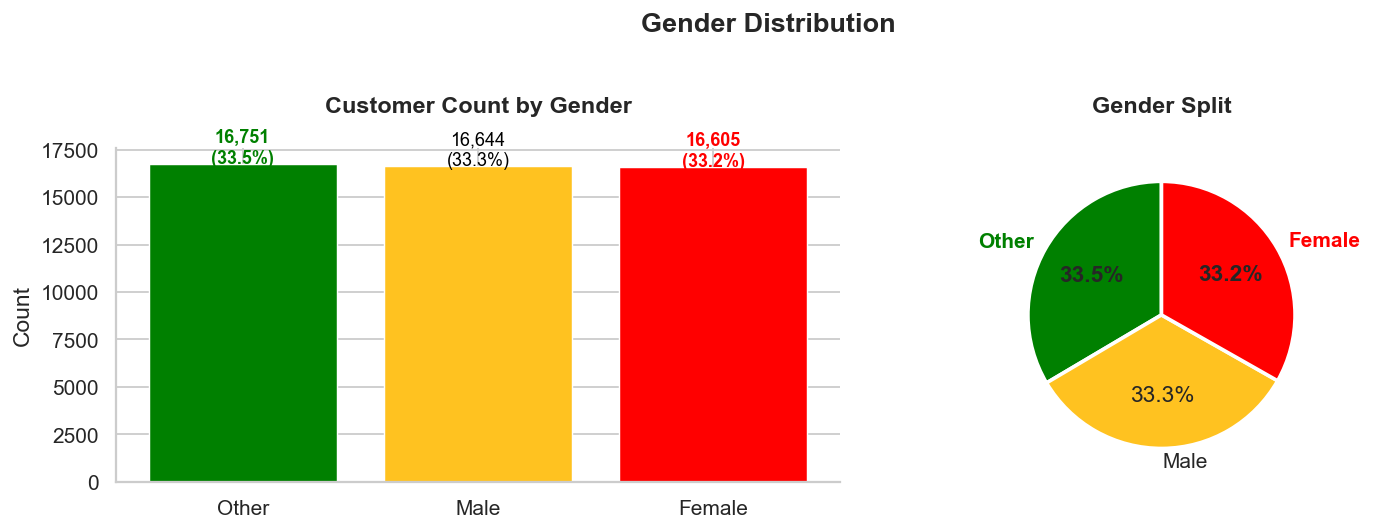

In [ ]:
if COL_GENDER:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    vc = df[COL_GENDER].value_counts()

    # ---- Find highest + lowest ----
    max_idx = vc.argmax()
    min_idx = vc.argmin()

    # base colors
    colors = PALETTE[:len(vc)].copy()

    # highlight
    colors[max_idx] = 'green'   # highest
    colors[min_idx] = 'red'     # lowest

    # ================= BAR CHART =================
    bars = axes[0].bar(
        vc.index,
        vc.values,
        color=colors,
        edgecolor='white',
        linewidth=0.8
    )

    axes[0].set_title(f'Customer Count by {COL_GENDER}', pad=20)
    axes[0].set_ylabel('Count')

    for i, v in enumerate(vc.values):

        if i == max_idx:
            txt_color = 'green'
            font_w = 'bold'
        elif i == min_idx:
            txt_color = 'red'
            font_w = 'bold'
        else:
            txt_color = 'black'
            font_w = 'normal'

        axes[0].text(
            i,
            v + 50,
            f'{v:,}\n({v/len(df)*100:.1f}%)',
            ha='center',
            fontsize=10,
            color=txt_color,
            fontweight=font_w
        )

    # ================= PIE CHART =================
    wedges, texts, autotexts = axes[1].pie(
        vc.values,
        labels=vc.index,
        autopct='%1.1f%%',
        colors=colors,
        startangle=90,
        wedgeprops={'edgecolor': 'white', 'linewidth': 2}
    )

    # Highlight labels
    texts[max_idx].set_color('green')
    texts[max_idx].set_fontweight('bold')

    texts[min_idx].set_color('red')
    texts[min_idx].set_fontweight('bold')

    autotexts[max_idx].set_fontweight('bold')
    autotexts[min_idx].set_fontweight('bold')

    axes[1].set_title(f'{COL_GENDER} Split', pad=20)

    plt.suptitle(
        'Gender Distribution',
        fontsize=15,
        fontweight='bold',
        y=1.02
    )

    plt.tight_layout()
    plt.show()

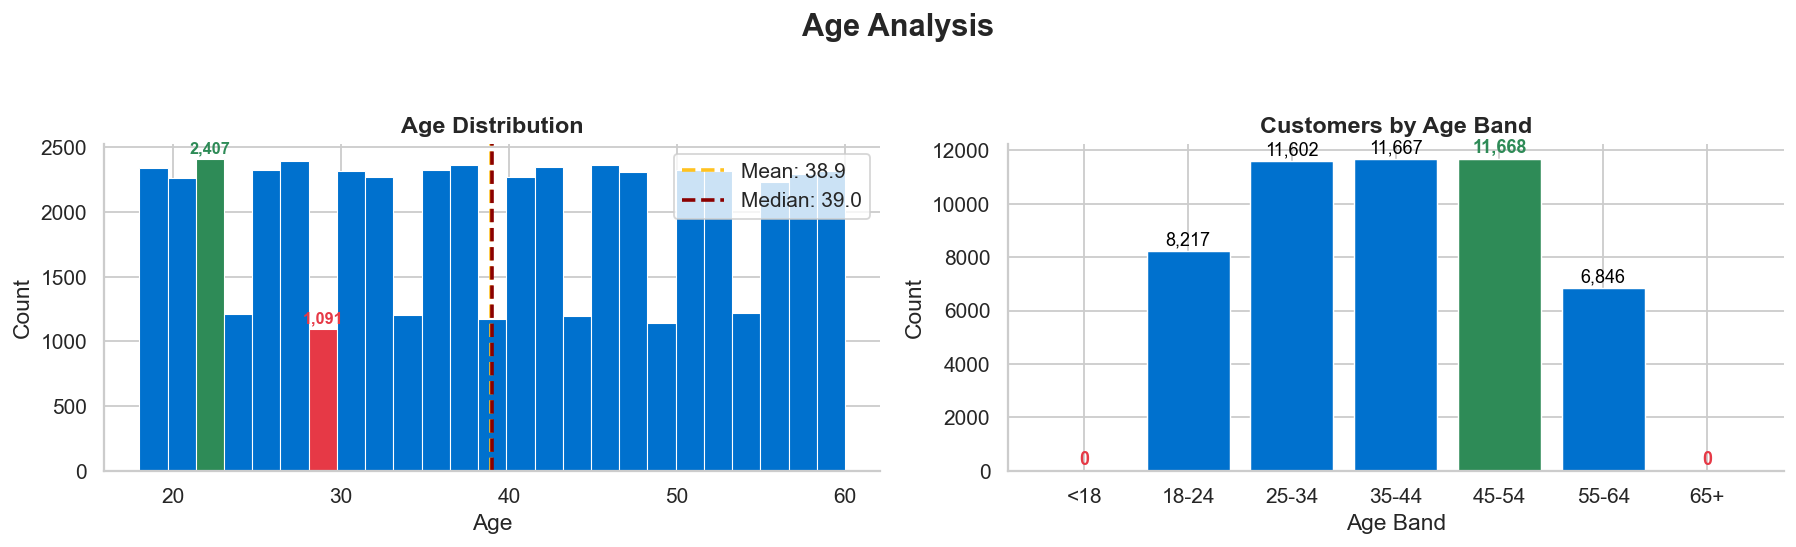

In [ ]:
if COL_AGE:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # =====================================
    # LEFT: AGE DISTRIBUTION (Histogram)
    # =====================================
    age = df[COL_AGE].dropna()

    counts, bins_hist = np.histogram(age, bins=25)
    centers = (bins_hist[:-1] + bins_hist[1:]) / 2

    max_bin = counts.argmax()
    min_bin = counts.argmin()

    # Color highest green, lowest red
    hist_colors = []
    for i in range(len(counts)):
        if i == max_bin:
            hist_colors.append('#2E8B57')   # green
        elif i == min_bin:
            hist_colors.append('#E63946')   # red
        else:
            hist_colors.append(WALMART_BLUE)

    width = np.diff(bins_hist)

    axes[0].bar(
        bins_hist[:-1],
        counts,
        width=width,
        align='edge',
        color=hist_colors,
        edgecolor='white',
        linewidth=0.6
    )

    mean_age = age.mean()
    median_age = age.median()

    axes[0].axvline(
        mean_age,
        color=WALMART_YELL,
        linestyle='--',
        linewidth=2,
        label=f"Mean: {mean_age:.1f}"
    )

    axes[0].axvline(
        median_age,
        color='#8B0000',
        linestyle='--',
        linewidth=2,
        label=f"Median: {median_age:.1f}"
    )

    # annotate max + min bins
    for i, v in enumerate(counts):
        if i in [max_bin, min_bin]:
            color = '#2E8B57' if i == max_bin else '#E63946'

            axes[0].text(
                centers[i],
                v + counts.max()*0.02,
                f'{v:,}',
                ha='center',
                fontsize=9,
                fontweight='bold',
                color=color
            )

    axes[0].set_title(
        f'{COL_AGE} Distribution',
        fontsize=13,
        fontweight='bold'
    )
    axes[0].set_xlabel(COL_AGE)
    axes[0].set_ylabel('Count')
    axes[0].legend()


    # =====================================
    # RIGHT: AGE BAND ANALYSIS
    # =====================================
    bins = [0, 18, 25, 35, 45, 55, 65, 120]
    labels = ['<18', '18-24', '25-34', '35-44', '45-54', '55-64', '65+']

    df['Age_Band'] = pd.cut(
        df[COL_AGE],
        bins=bins,
        labels=labels,
        right=False
    )

    ab_vc = df['Age_Band'].value_counts().sort_index()

    max_val = ab_vc.max()
    min_val = ab_vc.min()

    max_idx = ab_vc.idxmax()
    min_idx = ab_vc.idxmin()

    # colors
    colors = []
    for idx in ab_vc.index:
        if idx == max_idx:
            colors.append('#2E8B57')   # green
        elif idx == min_idx:
            colors.append('#E63946')   # red
        else:
            colors.append(WALMART_BLUE)

    bars = axes[1].bar(
        ab_vc.index.astype(str),
        ab_vc.values,
        color=colors,
        edgecolor='white',
        linewidth=0.8
    )

    axes[1].set_title(
        'Customers by Age Band',
        fontsize=13,
        fontweight='bold'
    )
    axes[1].set_xlabel('Age Band')
    axes[1].set_ylabel('Count')

    # labels
    for i, v in enumerate(ab_vc.values):

        if v == max_val:
            txt_color = '#2E8B57'
            weight = 'bold'
        elif v == min_val:
            txt_color = '#E63946'
            weight = 'bold'
        else:
            txt_color = 'black'
            weight = 'normal'

        axes[1].text(
            i,
            v + max_val*0.02,
            f'{v:,}',
            ha='center',
            fontsize=10,
            fontweight=weight,
            color=txt_color
        )

    # overall title
    plt.suptitle(
        'Age Analysis',
        fontsize=17,
        fontweight='bold',
        y=1.05
    )

    plt.tight_layout()
    plt.show()

In [ ]:


# no color display for age distribution
# if COL_AGE:
#     fig, axes = plt.subplots(1, 2, figsize=(14, 4))

#     # =========================
#     # LEFT: AGE DISTRIBUTION
#     # =========================
#     axes[0].hist(
#         df[COL_AGE].dropna(),
#         bins=25,
#         color=WALMART_BLUE,
#         edgecolor='white',
#         linewidth=0.6
#     )

#     mean_age = df[COL_AGE].mean()
#     median_age = df[COL_AGE].median()

#     axes[0].axvline(
#         mean_age,
#         color=WALMART_YELL,
#         linestyle='--',
#         linewidth=2,
#         label=f"Mean: {mean_age:.1f}"
#     )

#     axes[0].axvline(
#         median_age,
#         color='#E63946',
#         linestyle='--',
#         linewidth=2,
#         label=f"Median: {median_age:.1f}"
#     )

#     axes[0].set_title(
#         f'{COL_AGE} Distribution',
#         fontsize=13,
#         fontweight='bold',
#         pad=10
#     )
#     axes[0].set_xlabel(COL_AGE)
#     axes[0].set_ylabel('Count')
#     axes[0].legend()


#     # =========================
#     # RIGHT: AGE BAND ANALYSIS
#     # =========================
#     bins = [0, 18, 25, 35, 45, 55, 65, 120]
#     labels = ['<18', '18-24', '25-34', '35-44', '45-54', '55-64', '65+']

#     df['Age_Band'] = pd.cut(
#         df[COL_AGE],
#         bins=bins,
#         labels=labels,
#         right=False
#     )

#     ab_vc = df['Age_Band'].value_counts().sort_index()

#     total = ab_vc.sum()
#     max_val = ab_vc.max()
#     min_val = ab_vc.min()

#     max_idx = ab_vc.idxmax()
#     min_idx = ab_vc.idxmin()

#     # Color highest green, lowest red, others blue
#     colors = []
#     for idx in ab_vc.index:
#         if idx == max_idx:
#             colors.append('#2E8B57')   # green
#         elif idx == min_idx:
#             colors.append('#E63946')   # red
#         else:
#             colors.append(WALMART_BLUE)

#     bars = axes[1].bar(
#         ab_vc.index.astype(str),
#         ab_vc.values,
#         color=colors,
#         edgecolor='white',
#         linewidth=0.8
#     )

#     axes[1].set_title(
#         'Customers by Age Band',
#         fontsize=13,
#         fontweight='bold',
#         pad=18
#     )

#     axes[1].set_xlabel('Age Band')
#     axes[1].set_ylabel('Count')

#     # Labels above bars
#     for i, (idx, v) in enumerate(ab_vc.items()):
#         pct = (v / total) * 100

#         if idx == max_idx:
#             txt_color = '#2E8B57'
#             weight = 'bold'
#         elif idx == min_idx:
#             txt_color = '#E63946'
#             weight = 'bold'
#         else:
#             txt_color = 'black'
#             weight = 'normal'

#         axes[1].text(
#             i,
#             v + max_val * 0.015,
#             f'{v:,}\n({pct:.1f}%)',
#             ha='center',
#             fontsize=10,
#             fontweight=weight,
#             color=txt_color
#         )

#     # Improve spacing
#     axes[1].set_ylim(0, max_val * 1.18)

#     # Overall title
#     plt.suptitle(
#         'Age Analysis',
#         fontsize=17,
#         fontweight='bold',
#         y=1.05
#     )

#     plt.tight_layout()
#     plt.show()

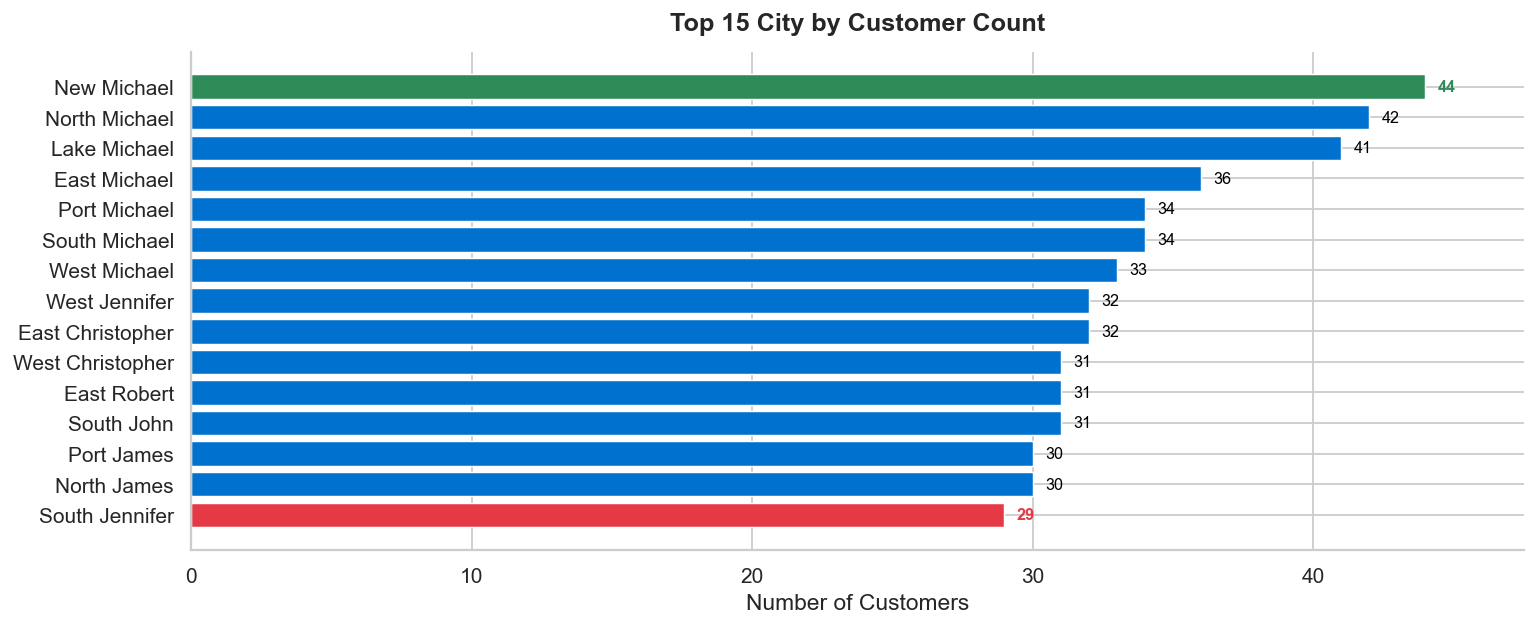

In [ ]:
# ── City / Location distribution ───────────────────────────────────────────
if COL_CITY:
    top_cities = df[COL_CITY].value_counts().head(15)

    max_val = top_cities.max()
    min_val = top_cities.min()
    max_city = top_cities.idxmax()
    min_city = top_cities.idxmin()

    # dynamic colors
    colors = [
        '#2E8B57' if city == max_city else   # highest → green
        '#E63946' if city == min_city else   # lowest → red
        WALMART_BLUE                          # others → blue
        for city in top_cities.index
    ]

    fig, ax = plt.subplots(figsize=(12, 5))

    bars = ax.barh(
        top_cities.index[::-1],
        top_cities.values[::-1],
        color=colors[::-1],
        edgecolor='white',
        linewidth=0.8
    )

    offset = top_cities.max() * 0.01

    # value labels
    for bar, city, val in zip(
        bars,
        top_cities.index[::-1],
        top_cities.values[::-1]
    ):

        # label color
        if city == max_city:
            txt_color = '#2E8B57'
            weight = 'bold'
        elif city == min_city:
            txt_color = '#E63946'
            weight = 'bold'
        else:
            txt_color = 'black'
            weight = 'normal'

        ax.text(
            bar.get_width() + offset,
            bar.get_y() + bar.get_height()/2,
            f'{val:,}',
            va='center',
            ha='left',
            fontsize=9,
            fontweight=weight,
            color=txt_color
        )

    ax.set_title(
        f'Top 15 {COL_CITY} by Customer Count',
        fontsize=14,
        fontweight='bold',
        pad=12
    )

    ax.set_xlabel('Number of Customers')
    ax.set_xlim(0, top_cities.max() * 1.08)

    plt.tight_layout()
    plt.show()

## 4. Univariate Analysis — Purchase Behaviour

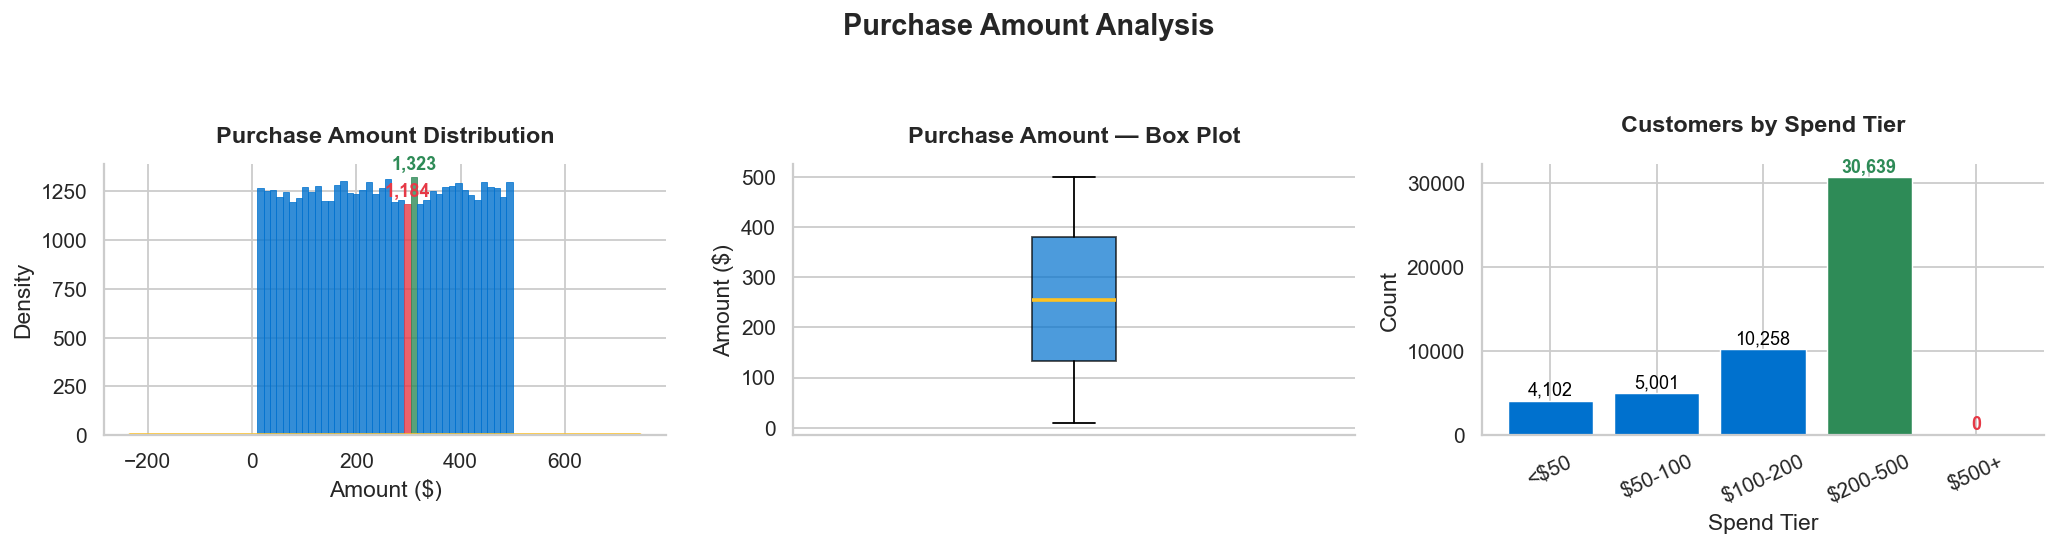

Mean   : $255.53
Median : $255.05
Std    : $141.57
Skew   : -0.003


In [ ]:
# ── Purchase amount distribution ───────────────────────────────────────────
if COL_AMOUNT:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    amount = df[COL_AMOUNT].dropna()

    # ======================================================
    # 1) HISTOGRAM + KDE → highlight highest & lowest bin
    # ======================================================
    counts, bins_hist, patches = axes[0].hist(
        amount,
        bins=40,
        color=WALMART_BLUE,
        edgecolor='white',
        linewidth=0.5,
        density=False,
        alpha=0.8
    )

    amount.plot.kde(ax=axes[0], color=WALMART_YELL, linewidth=2)

    # highest / lowest non-zero bin
    max_idx = counts.argmax()
    nonzero_idx = np.where(counts > 0)[0]
    min_idx = nonzero_idx[counts[nonzero_idx].argmin()]

    # recolor bars
    for i, patch in enumerate(patches):
        if i == max_idx:
            patch.set_color('#2E8B57')   # GREEN = highest
        elif i == min_idx:
            patch.set_color('#E63946')   # RED = lowest
        else:
            patch.set_color(WALMART_BLUE)

    # annotate only highest + lowest
    for idx in [max_idx, min_idx]:
        x = (bins_hist[idx] + bins_hist[idx + 1]) / 2
        y = counts[idx]

        axes[0].text(
            x,
            y + counts.max() * 0.03,
            f'{int(y):,}',
            ha='center',
            fontsize=10,
            fontweight='bold',
            color='#2E8B57' if idx == max_idx else '#E63946'
        )

    axes[0].set_title(
        'Purchase Amount Distribution',
        fontsize=13,
        fontweight='bold',
        pad=12
    )
    axes[0].set_xlabel('Amount ($)')


    # ======================================================
    # 2) BOX PLOT
    # ======================================================
    axes[1].boxplot(
        amount,
        vert=True,
        patch_artist=True,
        boxprops=dict(facecolor=WALMART_BLUE, alpha=0.7),
        medianprops=dict(color=WALMART_YELL, linewidth=2)
    )

    axes[1].set_title(
        'Purchase Amount — Box Plot',
        fontsize=13,
        fontweight='bold',
        pad=12
    )
    axes[1].set_ylabel('Amount ($)')
    axes[1].set_xticks([])


    # ======================================================
    # 3) SPEND TIERS → highlight highest & lowest
    # ======================================================
    max_amt = amount.max()

    bins_spend = [0, 50, 100, 200, 500]

    if max_amt > 500:
        bins_spend.append(1000)

    bins_spend.append(max_amt + 1)
    bins_spend = sorted(set(bins_spend))

    labels_map = {
        2: ['<$50', '$50+'],
        3: ['<$50', '$50-100', '$100+'],
        4: ['<$50', '$50-100', '$100-200', '$200+'],
        5: ['<$50', '$50-100', '$100-200', '$200-500', '$500+'],
        6: ['<$50', '$50-100', '$100-200', '$200-500', '$500-1k', '$1k+']
    }

    labels_spend = labels_map[len(bins_spend) - 1]

    df['Spend_Tier'] = pd.cut(
        df[COL_AMOUNT],
        bins=bins_spend,
        labels=labels_spend,
        right=False
    )

    st_vc = df['Spend_Tier'].value_counts().sort_index()

    # highest + lowest
    max_val = st_vc.max()
    min_val = st_vc.min()
    max_cat = st_vc.idxmax()
    min_cat = st_vc.idxmin()

    colors = []
    for cat in st_vc.index:
        if cat == max_cat:
            colors.append('#2E8B57')   # GREEN
        elif cat == min_cat:
            colors.append('#E63946')   # RED
        else:
            colors.append(WALMART_BLUE)

    bars = axes[2].bar(
        st_vc.index.astype(str),
        st_vc.values,
        color=colors,
        edgecolor='white',
        linewidth=0.8
    )

    axes[2].set_title(
        'Customers by Spend Tier',
        fontsize=13,
        fontweight='bold',
        pad=18
    )

    axes[2].set_xlabel('Spend Tier')
    axes[2].set_ylabel('Count')
    axes[2].tick_params(axis='x', rotation=25)

    # labels
    for i, v in enumerate(st_vc.values):
        is_max = v == max_val
        is_min = v == min_val

        axes[2].text(
            i,
            v + max_val * 0.02,
            f'{v:,}',
            ha='center',
            fontsize=10,
            fontweight='bold' if (is_max or is_min) else 'normal',
            color='#2E8B57' if is_max else '#E63946' if is_min else 'black'
        )

    plt.suptitle(
        'Purchase Amount Analysis',
        fontsize=16,
        fontweight='bold',
        y=1.05
    )

    plt.tight_layout()
    plt.show()

    print(f"Mean   : ${amount.mean():,.2f}")
    print(f"Median : ${amount.median():,.2f}")
    print(f"Std    : ${amount.std():,.2f}")
    print(f"Skew   : {amount.skew():.3f}")

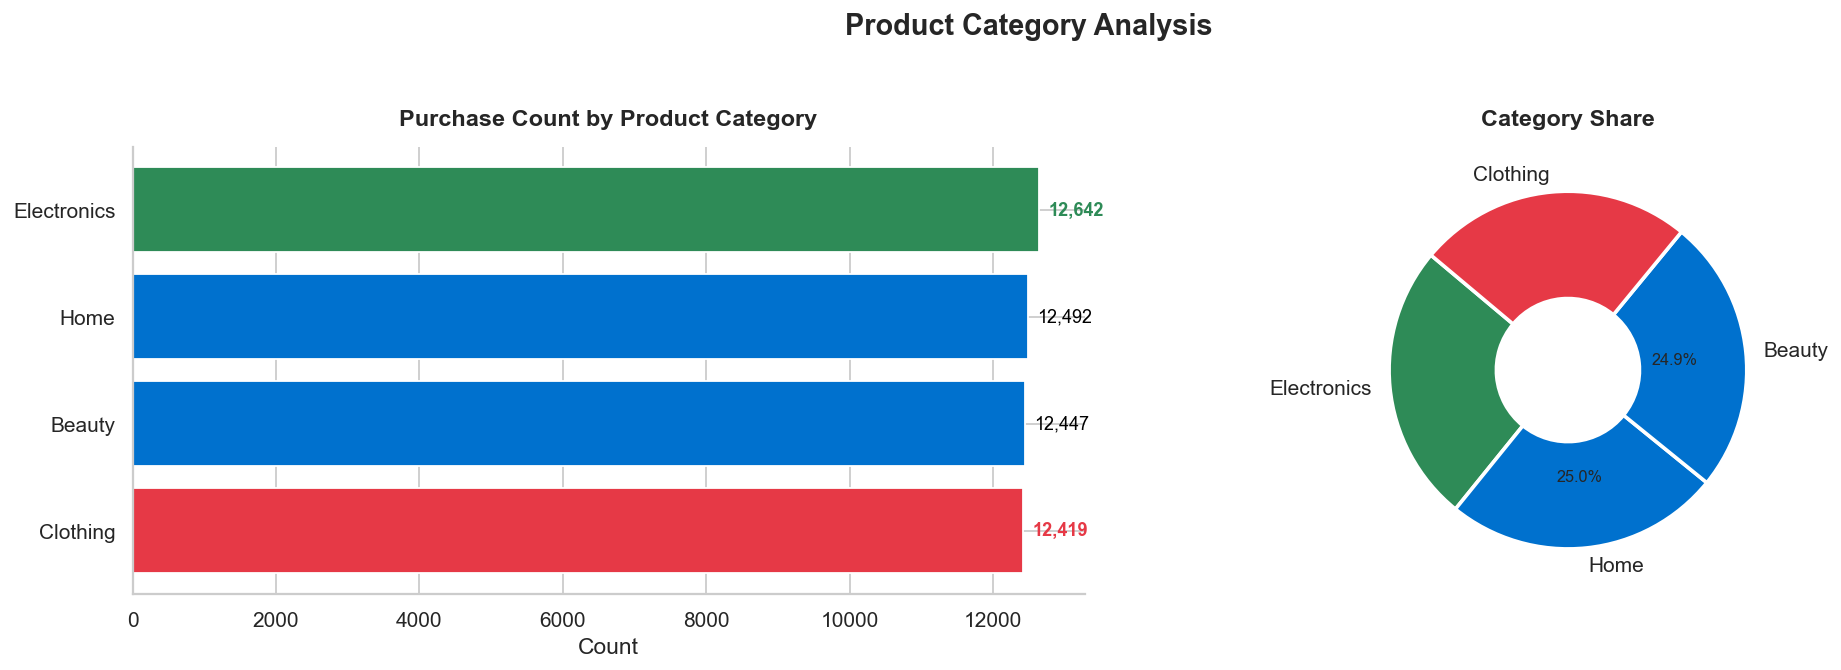

In [ ]:
# ── Product category distribution ──────────────────────────────────────────
if COL_CATEGORY:

    cat_vc = df[COL_CATEGORY].value_counts()

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    # =========================
    # Find highest / lowest
    # =========================
    max_val = cat_vc.max()
    min_val = cat_vc.min()

    max_idx = cat_vc.idxmax()
    min_idx = cat_vc.idxmin()

    # color mapping
    color_map = []
    for idx in cat_vc.index:
        if idx == max_idx:
            color_map.append('#2E8B57')   # green → highest
        elif idx == min_idx:
            color_map.append('#E63946')   # red → lowest
        else:
            color_map.append(WALMART_BLUE)

    # =========================
    # LEFT → Horizontal bar
    # =========================
    cat_rev = cat_vc[::-1]
    color_rev = color_map[::-1]

    bars = axes[0].barh(
        cat_rev.index,
        cat_rev.values,
        color=color_rev,
        edgecolor='white',
        linewidth=1
    )

    axes[0].set_title(
        'Purchase Count by Product Category',
        fontsize=13,
        fontweight='bold',
        pad=12
    )
    axes[0].set_xlabel('Count')

    # labels
    for i, (idx, v) in enumerate(cat_rev.items()):

        if idx == max_idx:
            txt_color = '#2E8B57'
            fw = 'bold'
        elif idx == min_idx:
            txt_color = '#E63946'
            fw = 'bold'
        else:
            txt_color = 'black'
            fw = 'normal'

        axes[0].text(
            v + max_val * 0.01,
            i,
            f'{v:,}',
            va='center',
            fontsize=10,
            fontweight=fw,
            color=txt_color
        )

    # =========================
    # RIGHT → Donut chart
    # =========================
    if len(cat_vc) <= 12:

        wedges, texts, autotexts = axes[1].pie(
            cat_vc.values,
            labels=cat_vc.index,
            autopct='%1.1f%%',
            startangle=140,
            colors=color_map,
            wedgeprops={
                'edgecolor': 'white',
                'linewidth': 2,
                'width': 0.6
            }
        )

        # highlight percentages
        for i, at in enumerate(autotexts):
            idx = cat_vc.index[i]

            if idx == max_idx:
                at.set_color('#2E8B57')
                at.set_fontweight('bold')
                at.set_fontsize(10)

            elif idx == min_idx:
                at.set_color('#E63946')
                at.set_fontweight('bold')
                at.set_fontsize(10)

            else:
                at.set_fontsize(9)

    else:
        top10 = cat_vc.head(10)

        top_colors = []
        for idx in top10.index:
            if idx == max_idx:
                top_colors.append('#2E8B57')
            elif idx == min_idx:
                top_colors.append('#E63946')
            else:
                top_colors.append(WALMART_BLUE)

        wedges, texts, autotexts = axes[1].pie(
            top10.values,
            labels=top10.index,
            autopct='%1.1f%%',
            colors=top_colors,
            wedgeprops={
                'edgecolor': 'white',
                'linewidth': 2,
                'width': 0.6
            }
        )

    axes[1].set_title(
        'Category Share',
        fontsize=13,
        fontweight='bold',
        pad=12
    )

    # overall heading
    plt.suptitle(
        'Product Category Analysis',
        fontsize=16,
        fontweight='bold',
        y=1.03
    )

    plt.tight_layout()
    plt.show()

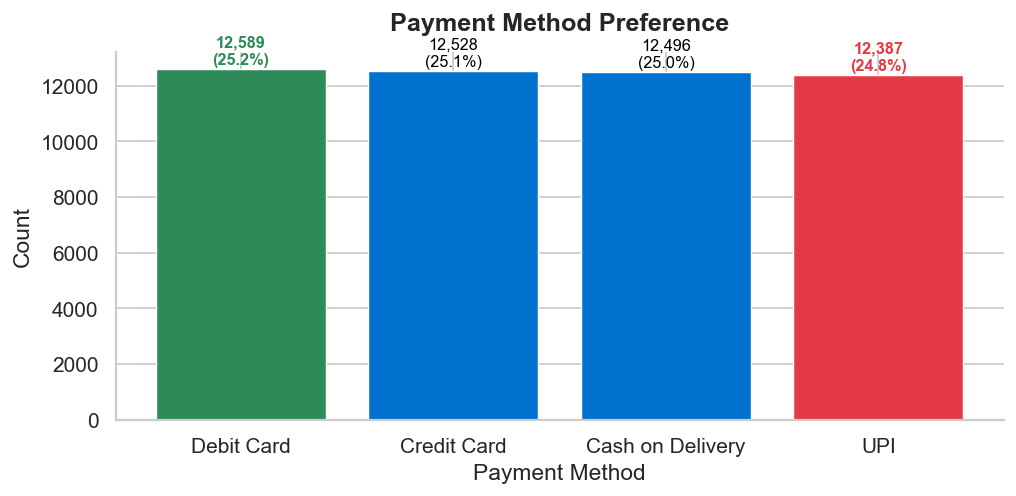

In [ ]:
# ── Payment method distribution ────────────────────────────────────────────
if COL_PAYMENT:
    pay_vc = df[COL_PAYMENT].value_counts()

    # identify highest / lowest
    max_val = pay_vc.max()
    min_val = pay_vc.min()

    max_idx = pay_vc.idxmax()
    min_idx = pay_vc.idxmin()

    # assign colors
    colors = []
    for method in pay_vc.index:
        if method == max_idx:
            colors.append('#2E8B57')   # green = highest
        elif method == min_idx:
            colors.append('#E63946')   # red = lowest
        else:
            colors.append(WALMART_BLUE)

    fig, ax = plt.subplots(figsize=(8, 4))

    bars = ax.bar(
        pay_vc.index,
        pay_vc.values,
        color=colors,
        edgecolor='white',
        linewidth=0.8
    )

    # labels
    for bar, method, val in zip(bars, pay_vc.index, pay_vc.values):

        if method == max_idx:
            txt_color = '#2E8B57'
            fw = 'bold'
        elif method == min_idx:
            txt_color = '#E63946'
            fw = 'bold'
        else:
            txt_color = 'black'
            fw = 'normal'

        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + max_val * 0.015,
            f'{val:,}\n({val/len(df)*100:.1f}%)',
            ha='center',
            fontsize=9,
            color=txt_color,
            fontweight=fw
        )

    ax.set_title(
        'Payment Method Preference',
        fontsize=14,
        fontweight='bold',
        pad=12
    )

    ax.set_ylabel('Count')
    ax.set_xlabel('Payment Method')

    plt.tight_layout()
    plt.show()

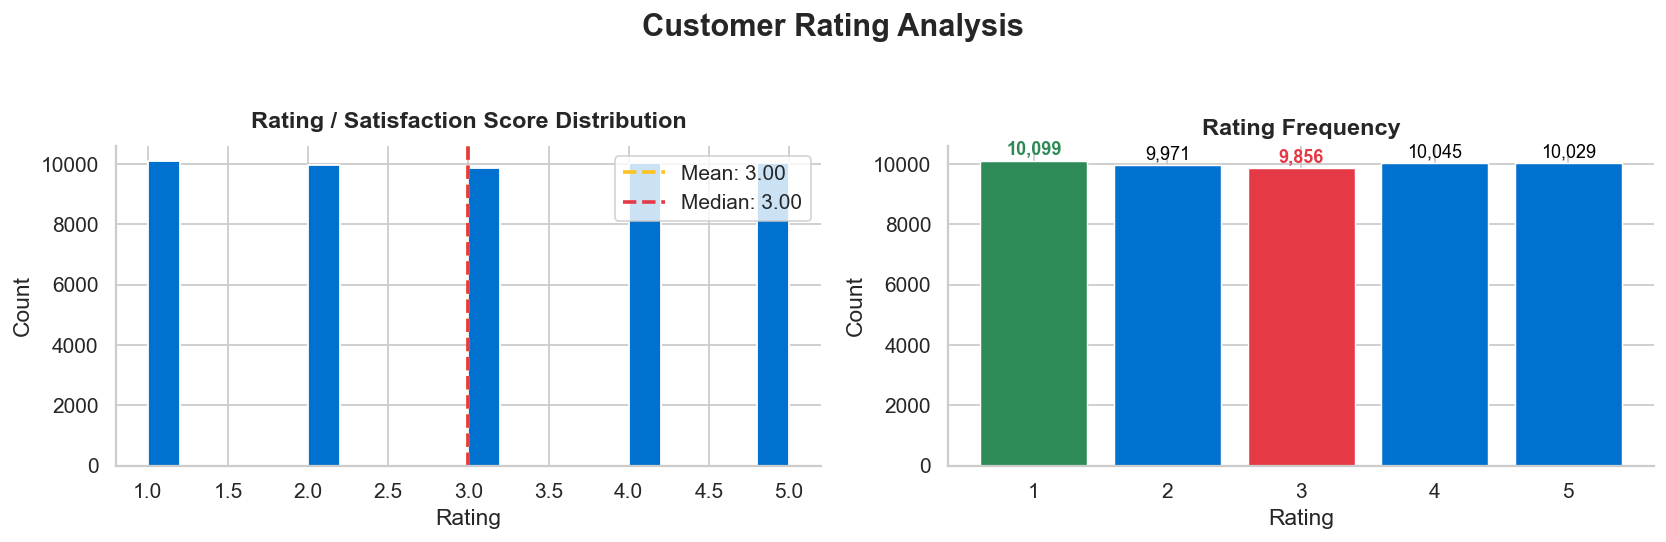

In [ ]:
# ── Rating / Satisfaction distribution ────────────────────────────────────
if COL_RATING:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    # ==================================================
    # LEFT: HISTOGRAM
    # ==================================================
    axes[0].hist(
        df[COL_RATING].dropna(),
        bins=20,
        color=WALMART_BLUE,
        edgecolor='white'
    )

    axes[0].axvline(
        df[COL_RATING].mean(),
        color=WALMART_YELL,
        linestyle='--',
        linewidth=2,
        label=f"Mean: {df[COL_RATING].mean():.2f}"
    )

    axes[0].axvline(
        df[COL_RATING].median(),
        color='#E63946',
        linestyle='--',
        linewidth=2,
        label=f"Median: {df[COL_RATING].median():.2f}"
    )

    axes[0].set_title(
        'Rating / Satisfaction Score Distribution',
        fontsize=13,
        fontweight='bold',
        pad=10
    )
    axes[0].set_xlabel('Rating')
    axes[0].set_ylabel('Count')
    axes[0].legend()

    # ==================================================
    # RIGHT: FREQUENCY / KDE
    # ==================================================
    if df[COL_RATING].nunique() <= 10:

        rv = df[COL_RATING].value_counts().sort_index()

        # highest / lowest
        max_val = rv.max()
        min_val = rv.min()

        max_idx = rv.idxmax()
        min_idx = rv.idxmin()

        # colors
        colors = []
        for idx in rv.index:
            if idx == max_idx:
                colors.append('#2E8B57')   # green
            elif idx == min_idx:
                colors.append('#E63946')   # red
            else:
                colors.append(WALMART_BLUE)

        bars = axes[1].bar(
            rv.index.astype(str),
            rv.values,
            color=colors,
            edgecolor='white',
            linewidth=0.8
        )

        axes[1].set_title(
            'Rating Frequency',
            fontsize=13,
            fontweight='bold'
        )
        axes[1].set_xlabel('Rating')
        axes[1].set_ylabel('Count')

        # labels
        for i, (idx, v) in enumerate(rv.items()):

            if idx == max_idx:
                txt_color = '#2E8B57'
                fw = 'bold'
            elif idx == min_idx:
                txt_color = '#E63946'
                fw = 'bold'
            else:
                txt_color = 'black'
                fw = 'normal'

            axes[1].text(
                i,
                v + max_val * 0.02,
                f'{v:,}',
                ha='center',
                fontsize=10,
                fontweight=fw,
                color=txt_color
            )

    else:
        # continuous rating → KDE
        df[COL_RATING].plot.kde(
            ax=axes[1],
            color=WALMART_BLUE,
            linewidth=2
        )

        mean_val = df[COL_RATING].mean()
        axes[1].axvline(
            mean_val,
            color='#2E8B57',
            linestyle='--',
            linewidth=2,
            label=f'Mean: {mean_val:.2f}'
        )

        axes[1].set_title(
            'Rating Density (KDE)',
            fontsize=13,
            fontweight='bold'
        )
        axes[1].set_xlabel('Rating')
        axes[1].legend()

    # overall title
    plt.suptitle(
        'Customer Rating Analysis',
        fontsize=17,
        fontweight='bold',
        y=1.04
    )

    plt.tight_layout()
    plt.show()

## 5. Bivariate Analysis — Demographics vs Spend

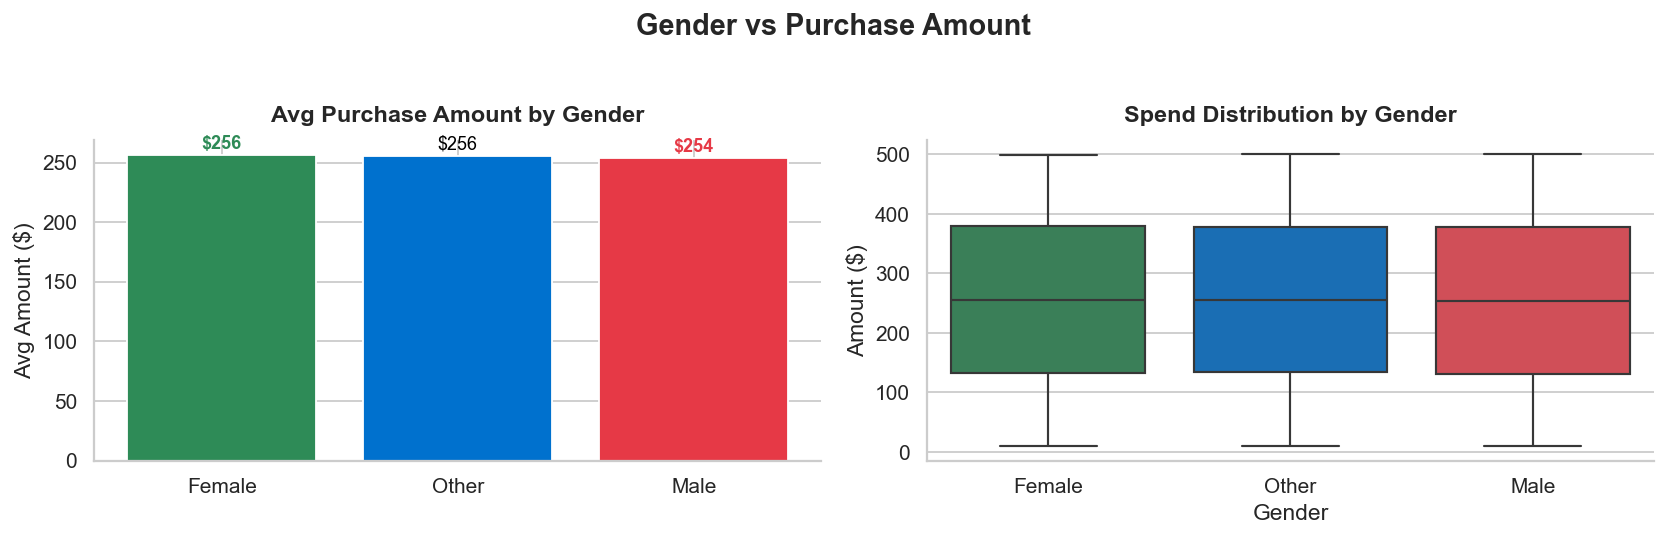

In [ ]:
# ── Average spend by gender ───────────────────────────────────────────────
if COL_GENDER and COL_AMOUNT:

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    # mean spend
    avg_gender = (
        df.groupby(COL_GENDER)[COL_AMOUNT]
        .mean()
        .sort_values(ascending=False)
    )

    # identify max/min
    max_idx = avg_gender.idxmax()
    min_idx = avg_gender.idxmin()

    # assign colors
    colors = []
    for gender in avg_gender.index:
        if gender == max_idx:
            colors.append('#2E8B57')   # green
        elif gender == min_idx:
            colors.append('#E63946')   # red
        else:
            colors.append(WALMART_BLUE)

    # =========================
    # LEFT: BAR CHART
    # =========================
    bars = axes[0].bar(
        avg_gender.index,
        avg_gender.values,
        color=colors,
        edgecolor='white',
        linewidth=1
    )

    # value labels
    for i, (gender, v) in enumerate(avg_gender.items()):

        if gender == max_idx:
            txt_color = '#2E8B57'
            fw = 'bold'
        elif gender == min_idx:
            txt_color = '#E63946'
            fw = 'bold'
        else:
            txt_color = 'black'
            fw = 'normal'

        axes[0].text(
            i,
            v + avg_gender.max() * 0.02,
            f'${v:,.0f}',
            ha='center',
            fontsize=10,
            fontweight=fw,
            color=txt_color
        )

    axes[0].set_title(
        f'Avg Purchase Amount by {COL_GENDER}',
        fontsize=13,
        fontweight='bold',
        pad=10
    )
    axes[0].set_ylabel('Avg Amount ($)')


    # =========================
    # RIGHT: BOXPLOT
    # =========================
    box_colors = {
        max_idx: '#2E8B57',
        min_idx: '#E63946'
    }

    palette = [
        box_colors.get(g, WALMART_BLUE)
        for g in df[COL_GENDER].unique()
    ]

    sns.boxplot(
        data=df,
        x=COL_GENDER,
        y=COL_AMOUNT,
        ax=axes[1],
        palette=palette,
        linewidth=1.2
    )

    axes[1].set_title(
        f'Spend Distribution by {COL_GENDER}',
        fontsize=13,
        fontweight='bold',
        pad=10
    )
    axes[1].set_ylabel('Amount ($)')


    # overall title
    plt.suptitle(
        'Gender vs Purchase Amount',
        fontsize=16,
        fontweight='bold',
        y=1.03
    )

    plt.tight_layout()
    plt.show()

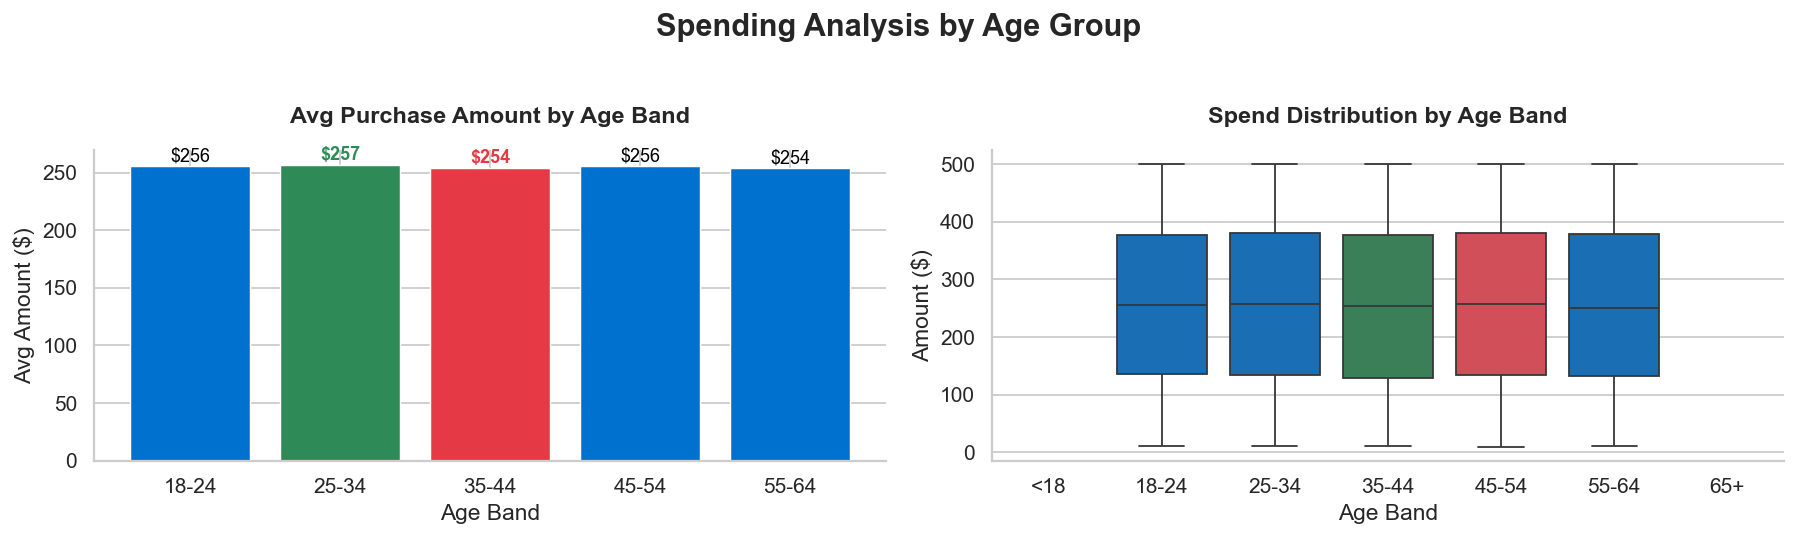

In [ ]:
# ── Spend by age band ─────────────────────────────────────────────────────
if 'Age_Band' in df.columns and COL_AMOUNT:

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # ==================================================
    # LEFT: AVG PURCHASE AMOUNT
    # ==================================================
    avg_age = df.groupby('Age_Band')[COL_AMOUNT].mean()

    max_idx = avg_age.idxmax()
    min_idx = avg_age.idxmin()
    max_val = avg_age.max()

    colors = []
    for idx in avg_age.index:
        if idx == max_idx:
            colors.append('#2E8B57')   # green
        elif idx == min_idx:
            colors.append('#E63946')   # red
        else:
            colors.append(WALMART_BLUE)

    bars = axes[0].bar(
        avg_age.index.astype(str),
        avg_age.values,
        color=colors,
        edgecolor='white',
        linewidth=0.8
    )

    # labels
    for i, (idx, v) in enumerate(avg_age.items()):

        if idx == max_idx:
            txt_color = '#2E8B57'
            fw = 'bold'
        elif idx == min_idx:
            txt_color = '#E63946'
            fw = 'bold'
        else:
            txt_color = 'black'
            fw = 'normal'

        axes[0].text(
            i,
            v + max_val * 0.015,
            f'${v:,.0f}',
            ha='center',
            fontsize=10,
            color=txt_color,
            fontweight=fw
        )

    axes[0].set_title(
        'Avg Purchase Amount by Age Band',
        fontsize=13,
        fontweight='bold',
        pad=15
    )
    axes[0].set_ylabel('Avg Amount ($)')
    axes[0].set_xlabel('Age Band')


    # ==================================================
    # RIGHT: SPEND DISTRIBUTION
    # ==================================================
    medians = df.groupby('Age_Band')[COL_AMOUNT].median()

    max_med = medians.idxmax()
    min_med = medians.idxmin()

    palette = []
    for idx in medians.index:
        if idx == max_med:
            palette.append('#2E8B57')
        elif idx == min_med:
            palette.append('#E63946')
        else:
            palette.append(WALMART_BLUE)

    sns.boxplot(
        data=df,
        x='Age_Band',
        y=COL_AMOUNT,
        ax=axes[1],
        palette=palette
    )

    axes[1].set_title(
        'Spend Distribution by Age Band',
        fontsize=13,
        fontweight='bold',
        pad=15
    )
    axes[1].set_ylabel('Amount ($)')
    axes[1].set_xlabel('Age Band')


    # overall title
    plt.suptitle(
        'Spending Analysis by Age Group',
        fontsize=17,
        fontweight='bold',
        y=1.03
    )

    plt.tight_layout()
    plt.show()

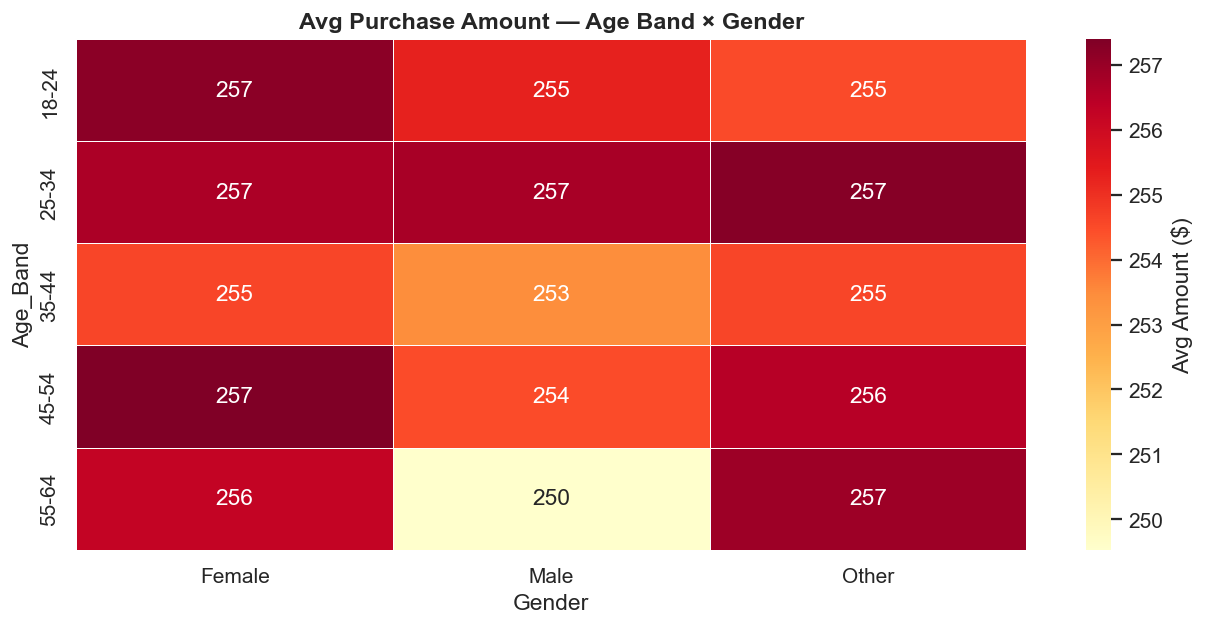

In [ ]:
# ── Gender × Age Band heatmap (avg spend) ─────────────────────────────────
if COL_GENDER and 'Age_Band' in df.columns and COL_AMOUNT:
    pivot = df.pivot_table(index='Age_Band', columns=COL_GENDER,
                           values=COL_AMOUNT, aggfunc='mean')
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlOrRd',
                linewidths=0.5, ax=ax, cbar_kws={'label': 'Avg Amount ($)'})
    ax.set_title('Avg Purchase Amount — Age Band × Gender', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

In [ ]:
# ── Loyalty / Membership vs spend ─────────────────────────────────────────
if COL_LOYALTY and COL_AMOUNT:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    
    avg_loy = df.groupby(COL_LOYALTY)[COL_AMOUNT].mean().sort_values(ascending=False)
    axes[0].bar(avg_loy.index.astype(str), avg_loy.values,
                color=PALETTE[:len(avg_loy)], edgecolor='white')
    for i, v in enumerate(avg_loy.values):
        axes[0].text(i, v + 1, f'${v:,.0f}', ha='center', fontweight='bold', fontsize=9)
    axes[0].set_title(f'Avg Purchase by {COL_LOYALTY}')
    axes[0].set_ylabel('Avg Amount ($)')
    axes[0].tick_params(axis='x', rotation=30)
    
    sns.violinplot(data=df, x=COL_LOYALTY, y=COL_AMOUNT, ax=axes[1],
                   palette=PALETTE[:df[COL_LOYALTY].nunique()], inner='quartile')
    axes[1].set_title(f'Spend Distribution by {COL_LOYALTY}')
    axes[1].set_ylabel('Amount ($)')
    axes[1].tick_params(axis='x', rotation=30)
    
    plt.suptitle('Loyalty Tier / Member Type vs Spend', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

## 6. Bivariate Analysis — Category & Payment Deep-Dive

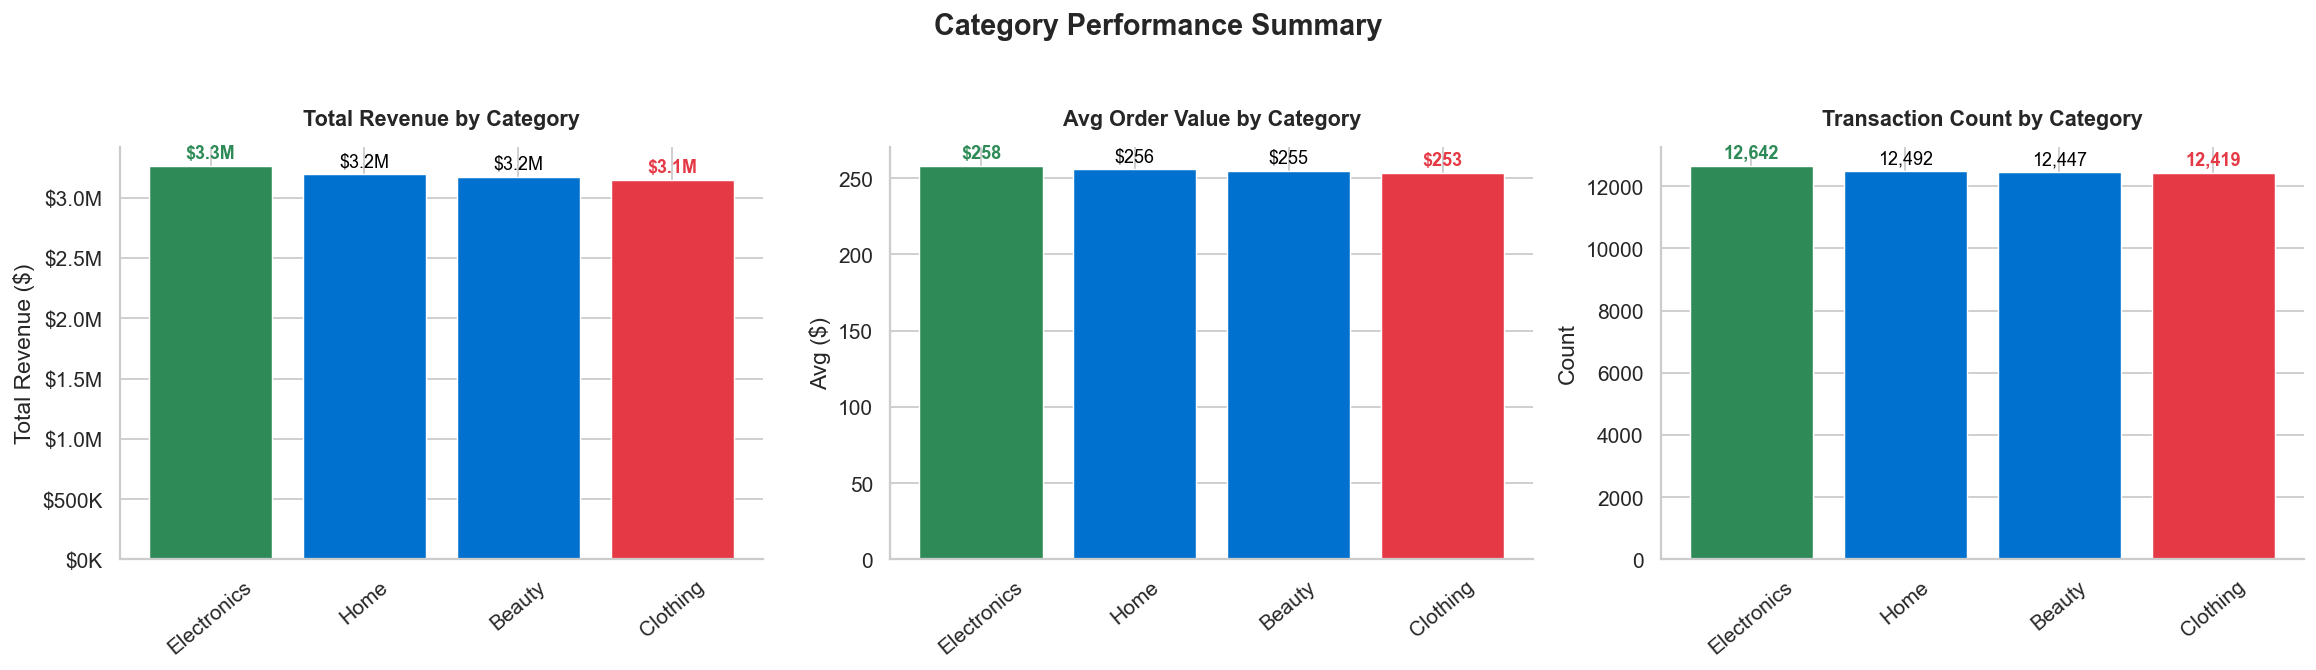

,Total_Revenue,Avg_Order_Value,Transaction_Count
Category,,,
Electronics,3260688.09,257.93,12642
Home,3195217.51,255.78,12492
Beauty,3174727.90,255.06,12447
Clothing,3145977.98,253.32,12419


In [ ]:
# ── Revenue by category ───────────────────────────────────────────────────
if COL_CATEGORY and COL_AMOUNT:

    cat_revenue = (
        df.groupby(COL_CATEGORY)[COL_AMOUNT]
        .agg(['sum', 'mean', 'count'])
        .round(2)
    )

    cat_revenue.columns = [
        'Total_Revenue',
        'Avg_Order_Value',
        'Transaction_Count'
    ]

    cat_revenue = cat_revenue.sort_values(
        'Total_Revenue',
        ascending=False
    )

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    WALMART_GREEN = '#2E8B57'
    WALMART_RED   = '#E63946'

    # helper for coloring + labels
    def plot_highlight_bar(ax, series, title, ylabel, money=False):

        max_idx = series.idxmax()
        min_idx = series.idxmin()
        max_val = series.max()

        colors = []
        for idx in series.index:
            if idx == max_idx:
                colors.append(WALMART_GREEN)
            elif idx == min_idx:
                colors.append(WALMART_RED)
            else:
                colors.append(WALMART_BLUE)

        bars = ax.bar(
            series.index.astype(str),
            series.values,
            color=colors,
            edgecolor='white',
            linewidth=0.8
        )

        ax.set_title(
            title,
            fontsize=12,
            fontweight='bold',
            pad=12
        )

        ax.set_ylabel(ylabel)
        ax.tick_params(axis='x', rotation=40)

        # value labels
        for i, (idx, val) in enumerate(series.items()):

            if idx == max_idx:
                txt_color = WALMART_GREEN
                fw = 'bold'
            elif idx == min_idx:
                txt_color = WALMART_RED
                fw = 'bold'
            else:
                txt_color = 'black'
                fw = 'normal'

            # label formatting
            if money:
                if val >= 1_000_000:
                    label = f'${val/1e6:.1f}M'
                elif val >= 1_000:
                    label = f'${val/1e3:.0f}K'
                else:
                    label = f'${val:.0f}'
            else:
                if val >= 1000:
                    label = f'{val:,.0f}'
                else:
                    label = f'{val:.2f}' if val % 1 else f'{val:.0f}'

            ax.text(
                i,
                val + max_val * 0.02,
                label,
                ha='center',
                fontsize=10,
                fontweight=fw,
                color=txt_color
            )

        return ax


    # 1) Revenue
    plot_highlight_bar(
        axes[0],
        cat_revenue['Total_Revenue'],
        'Total Revenue by Category',
        'Total Revenue ($)',
        money=True
    )

    axes[0].yaxis.set_major_formatter(
        mticker.FuncFormatter(
            lambda x, _: f'${x/1e6:.1f}M'
            if x >= 1e6
            else f'${x/1e3:.0f}K'
        )
    )


    # 2) AOV
    plot_highlight_bar(
        axes[1],
        cat_revenue['Avg_Order_Value'],
        'Avg Order Value by Category',
        'Avg ($)',
        money=True
    )


    # 3) Transactions
    plot_highlight_bar(
        axes[2],
        cat_revenue['Transaction_Count'],
        'Transaction Count by Category',
        'Count',
        money=False
    )


    plt.suptitle(
        'Category Performance Summary',
        fontsize=16,
        fontweight='bold',
        y=1.03
    )

    plt.tight_layout()
    plt.show()

    display(cat_revenue)

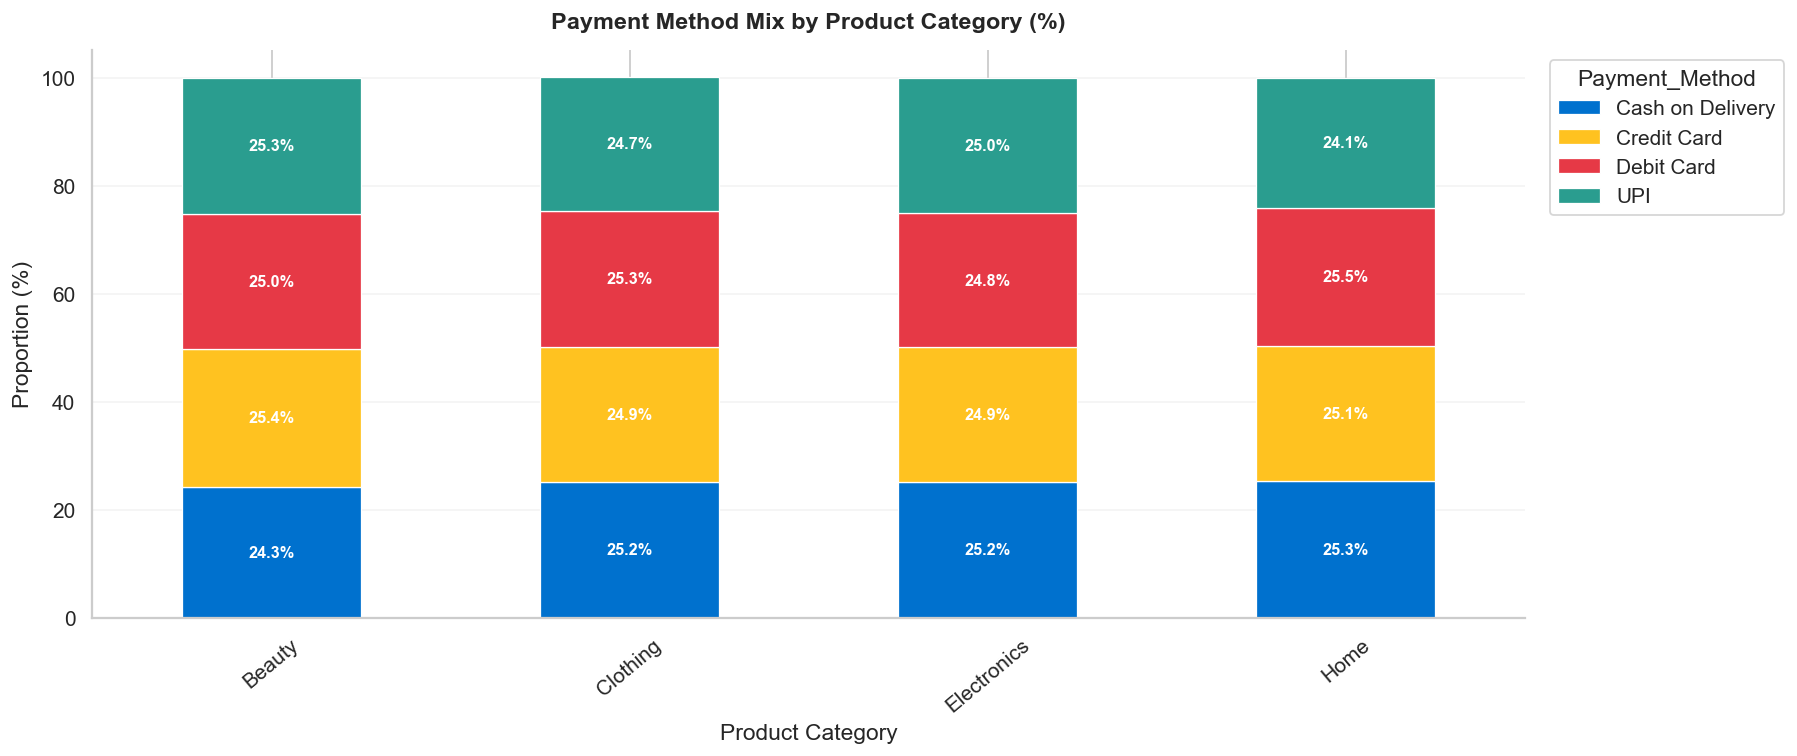

In [ ]:
# ── Payment method × category ─────────────────────────────────────────────
if COL_PAYMENT and COL_CATEGORY:

    ct = (
        pd.crosstab(
            df[COL_CATEGORY],
            df[COL_PAYMENT],
            normalize='index'
        ) * 100
    ).round(1)

    fig, ax = plt.subplots(figsize=(14, 6))

    # stacked bar
    bars = ct.plot(
        kind='bar',
        stacked=True,
        ax=ax,
        color=PALETTE[:df[COL_PAYMENT].nunique()],
        edgecolor='white',
        linewidth=0.7
    )

    # ==================================================
    # DATA LABELS
    # ==================================================
    for container in ax.containers:

        labels = []

        for bar in container:
            height = bar.get_height()

            # avoid clutter on tiny slices
            if height >= 5:
                labels.append(f'{height:.1f}%')
            else:
                labels.append('')

        ax.bar_label(
            container,
            labels=labels,
            label_type='center',
            fontsize=9,
            fontweight='bold',
            color='white'
        )

    # ==================================================
    # STYLING
    # ==================================================
    ax.set_title(
        'Payment Method Mix by Product Category (%)',
        fontsize=13,
        fontweight='bold',
        pad=12
    )

    ax.set_ylabel('Proportion (%)')
    ax.set_xlabel('Product Category')
    ax.tick_params(axis='x', rotation=40)

    ax.legend(
        title=COL_PAYMENT,
        bbox_to_anchor=(1.01, 1),
        loc='upper left'
    )

    ax.grid(axis='y', alpha=0.2)

    plt.tight_layout()
    plt.show()

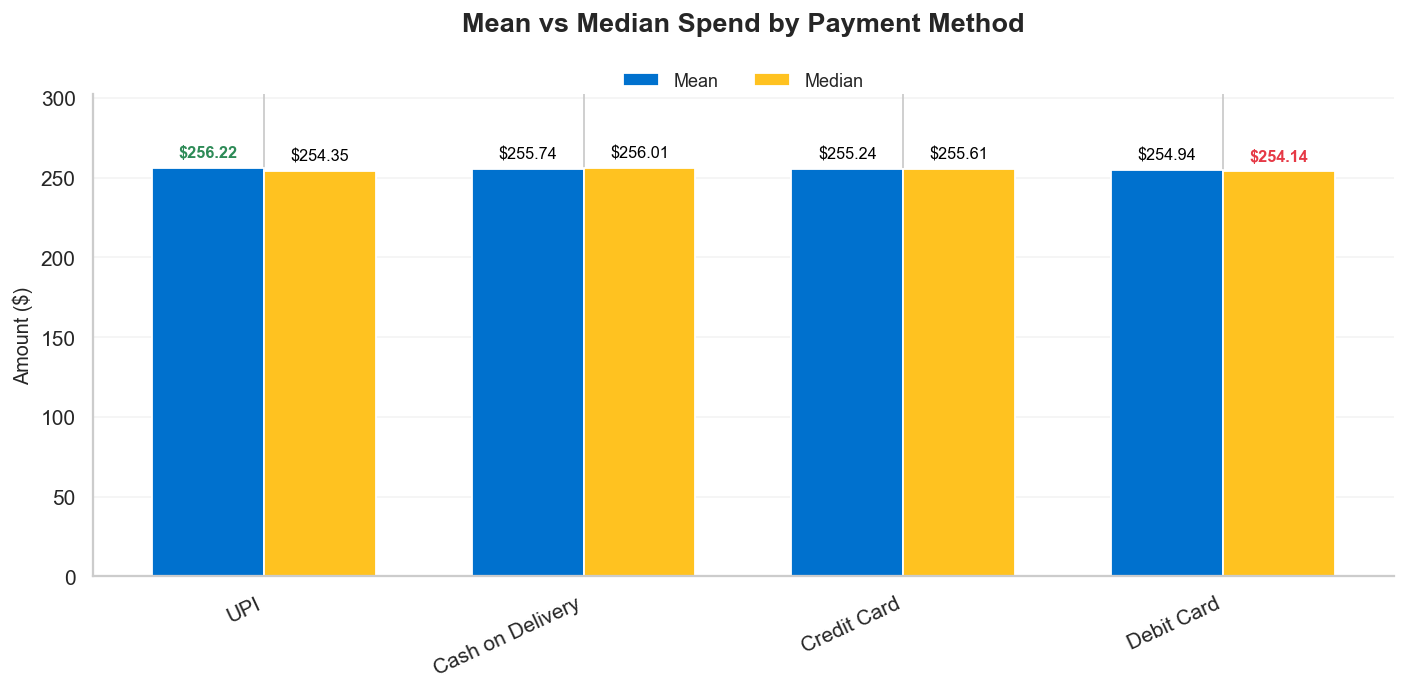

,Avg,Median,Count
Payment_Method,,,
UPI,256.22,254.35,12387
Cash on Delivery,255.74,256.02,12496
Credit Card,255.24,255.61,12528
Debit Card,254.94,254.14,12589


In [ ]:
# ── Avg spend by payment method ───────────────────────────────────────────
if COL_PAYMENT and COL_AMOUNT:

    pay_stats = df.groupby(COL_PAYMENT)[COL_AMOUNT].agg(
        ['mean', 'median', 'count']
    )

    pay_stats.columns = ['Avg', 'Median', 'Count']
    pay_stats = pay_stats.sort_values('Avg', ascending=False)

    fig, ax = plt.subplots(figsize=(11, 5.5))

    x = np.arange(len(pay_stats))
    width = 0.35

    WALMART_GREEN = '#2E8B57'
    WALMART_RED   = '#E63946'

    # =====================================================
    # BARS
    # =====================================================
    bars1 = ax.bar(
        x - width/2,
        pay_stats['Avg'],
        width,
        label='Mean',
        color=WALMART_BLUE,
        edgecolor='white',
        linewidth=1
    )

    bars2 = ax.bar(
        x + width/2,
        pay_stats['Median'],
        width,
        label='Median',
        color=WALMART_YELL,
        edgecolor='white',
        linewidth=1
    )

    # overall highest / lowest
    all_vals = pd.concat([
        pay_stats['Avg'],
        pay_stats['Median']
    ])

    highest = all_vals.max()
    lowest = all_vals.min()

    ymax = max(
        pay_stats['Avg'].max(),
        pay_stats['Median'].max()
    )

    # =====================================================
    # LABEL FUNCTION
    # =====================================================
    def add_labels(bars):

        for bar in bars:

            val = bar.get_height()

            if np.isclose(val, highest):
                color = WALMART_GREEN
                weight = 'bold'
            elif np.isclose(val, lowest):
                color = WALMART_RED
                weight = 'bold'
            else:
                color = 'black'
                weight = 'normal'

            ax.text(
                bar.get_x() + bar.get_width()/2,
                val + ymax * 0.018,
                f'${val:.2f}',
                ha='center',
                va='bottom',
                fontsize=9,
                color=color,
                fontweight=weight
            )

    add_labels(bars1)
    add_labels(bars2)

    # =====================================================
    # STYLING
    # =====================================================
    ax.set_xticks(x)
    ax.set_xticklabels(
        pay_stats.index,
        rotation=25,
        ha='right'
    )

    ax.set_title(
        'Mean vs Median Spend by Payment Method',
        fontsize=15,
        fontweight='bold',
        pad=35
    )

    ax.set_ylabel('Amount ($)', fontsize=11)

    # add headroom for labels
    ax.set_ylim(0, ymax * 1.18)

    # clean grid
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)

    # =====================================================
    # LEGEND (TOP CENTER, OUTSIDE)
    # =====================================================
    ax.legend(
        loc='upper center',
        bbox_to_anchor=(0.5, 1.08),
        ncol=2,
        frameon=False,
        fontsize=10
    )

    plt.tight_layout()
    plt.show()

    display(pay_stats.round(2))

## 7. Time-Series & Seasonality Analysis

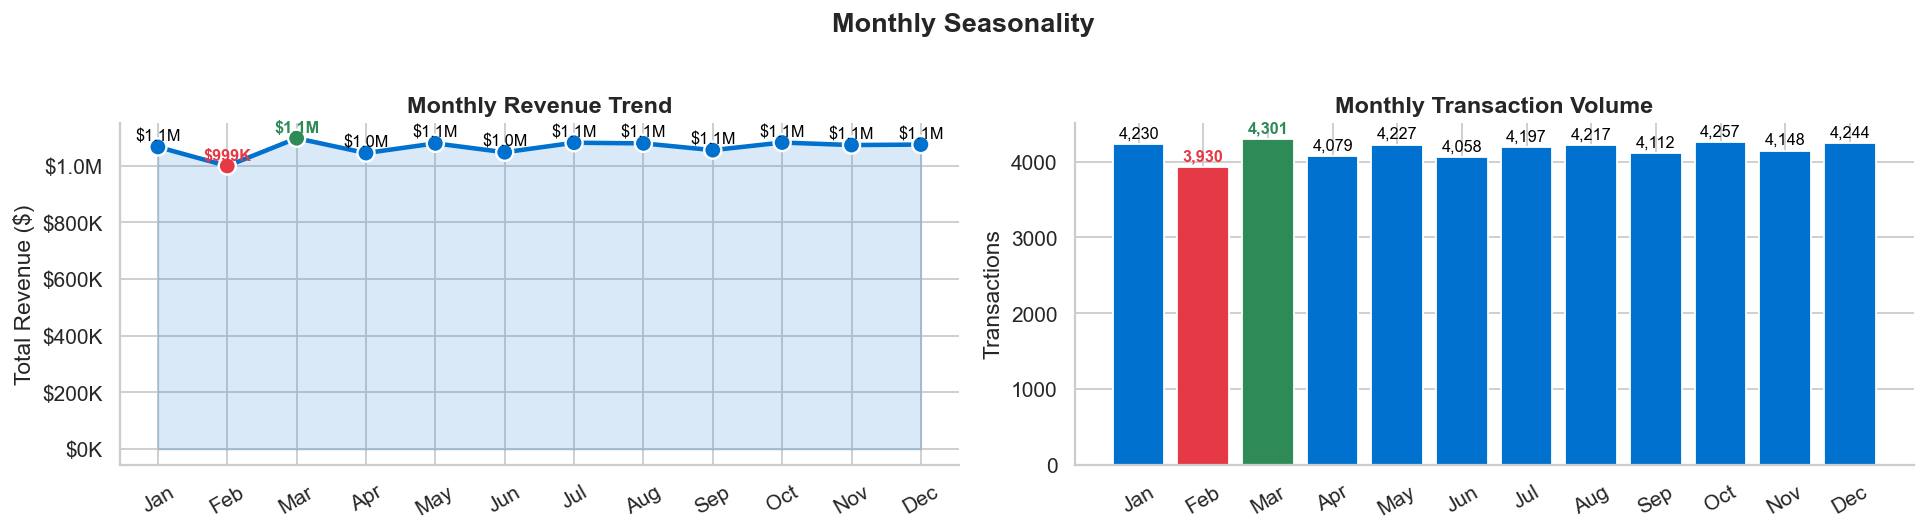

In [ ]:
# ── Monthly revenue trend ─────────────────────────────────────────────────
if 'Month' in df.columns and COL_AMOUNT:

    month_order = ['Jan','Feb','Mar','Apr','May','Jun',
                   'Jul','Aug','Sep','Oct','Nov','Dec']

    monthly = df.groupby('Month_Name')[COL_AMOUNT].agg(['sum','count','mean'])
    monthly.columns = ['Revenue','Transactions','Avg_Spend']
    monthly = monthly.reindex([m for m in month_order if m in monthly.index])

    fig, axes = plt.subplots(1, 2, figsize=(15, 4))

    WALMART_GREEN = '#2E8B57'
    WALMART_RED = '#E63946'


    # ==================================================
    # LEFT: Monthly Revenue Trend
    # ==================================================
    revenue = monthly['Revenue']

    max_month = revenue.idxmax()
    min_month = revenue.idxmin()
    max_val = revenue.max()

    # base line
    axes[0].plot(
        monthly.index,
        revenue,
        color=WALMART_BLUE,
        linewidth=2.5,
        zorder=1
    )

    # fill area
    axes[0].fill_between(
        range(len(monthly)),
        revenue.values,
        alpha=0.15,
        color=WALMART_BLUE
    )

    # custom point colors
    point_colors = [
        WALMART_GREEN if m == max_month else
        WALMART_RED if m == min_month else
        WALMART_BLUE
        for m in revenue.index
    ]

    axes[0].scatter(
        range(len(monthly)),
        revenue.values,
        s=90,
        c=point_colors,
        edgecolors='white',
        linewidth=1.3,
        zorder=3
    )

    # labels
    for i, (month, value) in enumerate(revenue.items()):

        if month == max_month:
            txt_color = WALMART_GREEN
            fw = 'bold'
        elif month == min_month:
            txt_color = WALMART_RED
            fw = 'bold'
        else:
            txt_color = 'black'
            fw = 'normal'

        label = (
            f'${value/1e6:.1f}M'
            if value >= 1_000_000
            else f'${value/1e3:.0f}K'
        )

        axes[0].text(
            i,
            value + max_val * 0.02,
            label,
            ha='center',
            fontsize=9,
            fontweight=fw,
            color=txt_color
        )

    axes[0].set_xticks(range(len(monthly)))
    axes[0].set_xticklabels(monthly.index, rotation=30)
    axes[0].set_title('Monthly Revenue Trend')
    axes[0].set_ylabel('Total Revenue ($)')
    axes[0].yaxis.set_major_formatter(
        mticker.FuncFormatter(
            lambda x,_: f'${x/1e6:.1f}M'
            if x >= 1e6 else f'${x/1e3:.0f}K'
        )
    )


    # ==================================================
    # RIGHT: Monthly Transaction Volume
    # ==================================================
    transactions = monthly['Transactions']

    max_month_txn = transactions.idxmax()
    min_month_txn = transactions.idxmin()
    max_txn = transactions.max()

    bar_colors = [
        WALMART_GREEN if m == max_month_txn else
        WALMART_RED if m == min_month_txn else
        WALMART_BLUE
        for m in transactions.index
    ]

    axes[1].bar(
        range(len(monthly)),
        transactions.values,
        color=bar_colors,
        edgecolor='white'
    )

    # labels
    for i, (month, value) in enumerate(transactions.items()):

        if month == max_month_txn:
            txt_color = WALMART_GREEN
            fw = 'bold'
        elif month == min_month_txn:
            txt_color = WALMART_RED
            fw = 'bold'
        else:
            txt_color = 'black'
            fw = 'normal'

        axes[1].text(
            i,
            value + max_txn * 0.02,
            f'{value:,.0f}',
            ha='center',
            fontsize=9,
            fontweight=fw,
            color=txt_color
        )

    axes[1].set_xticks(range(len(monthly)))
    axes[1].set_xticklabels(monthly.index, rotation=30)
    axes[1].set_title('Monthly Transaction Volume')
    axes[1].set_ylabel('Transactions')


    plt.suptitle(
        'Monthly Seasonality',
        fontsize=15,
        fontweight='bold',
        y=1.02
    )

    plt.tight_layout()
    plt.show()

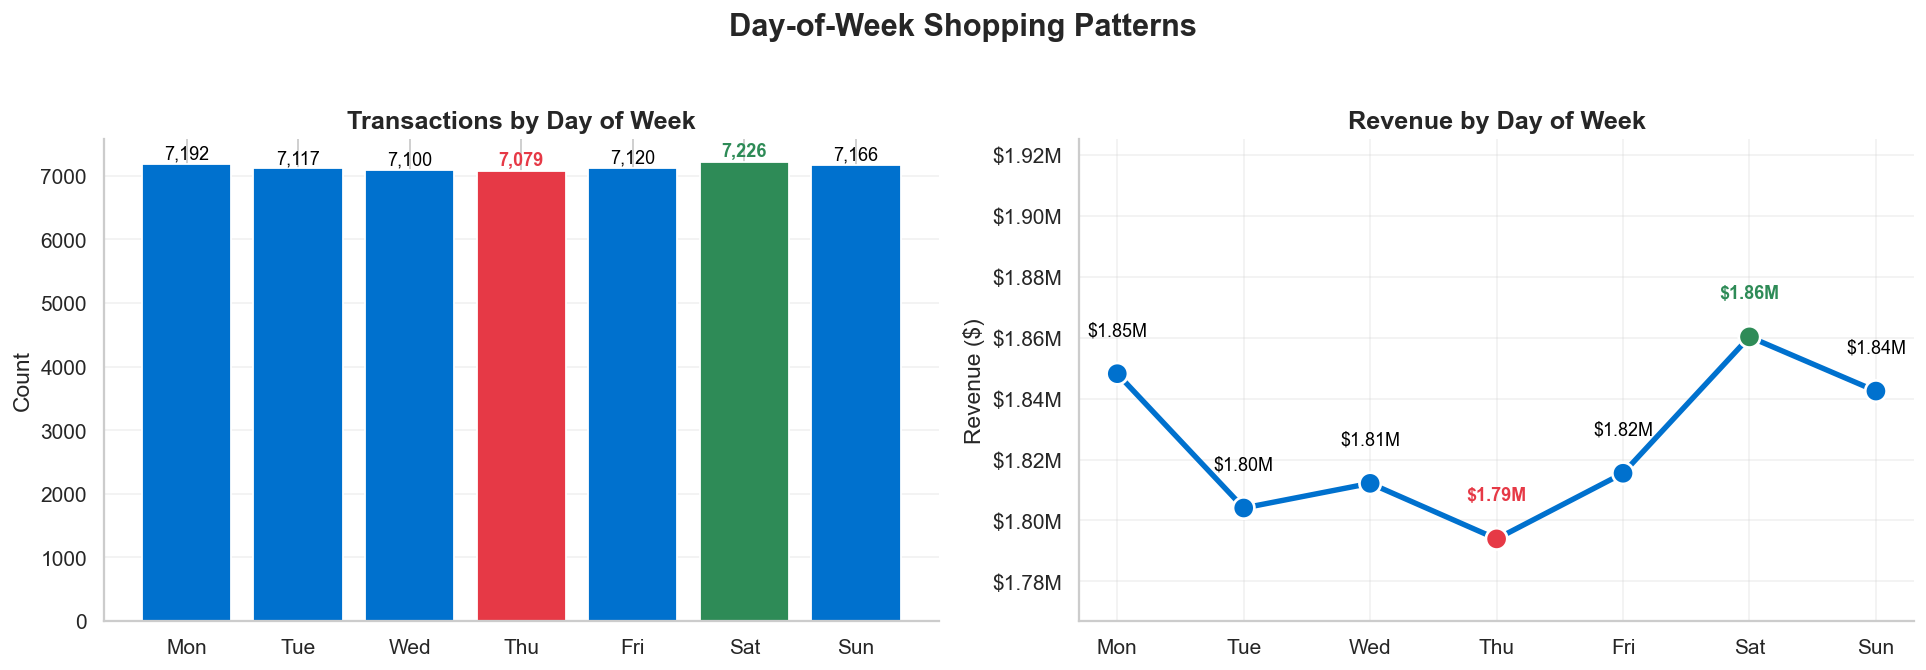

In [ ]:
# ── Day-of-week patterns ──────────────────────────────────────────────────
if 'DayOfWeek' in df.columns and COL_AMOUNT:

    day_order = [
        'Monday', 'Tuesday', 'Wednesday',
        'Thursday', 'Friday', 'Saturday', 'Sunday'
    ]

    dow = df.groupby('DayOfWeek')[COL_AMOUNT].agg(['sum', 'count'])
    dow.columns = ['Revenue', 'Transactions']
    dow = dow.reindex([d for d in day_order if d in dow.index])

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    WALMART_GREEN = '#2E8B57'
    WALMART_RED   = '#E63946'


    # ==========================================================
    # LEFT : TRANSACTIONS
    # ==========================================================
    txn = dow['Transactions']
    txn_max_idx = txn.idxmax()
    txn_min_idx = txn.idxmin()
    txn_max = txn.max()

    bar_colors = [
        WALMART_GREEN if i == txn_max_idx else
        WALMART_RED if i == txn_min_idx else
        WALMART_BLUE
        for i in txn.index
    ]

    bars = axes[0].bar(
        range(len(txn)),
        txn.values,
        color=bar_colors,
        edgecolor='white',
        linewidth=1
    )

    for i, (idx, val) in enumerate(txn.items()):

        color = (
            WALMART_GREEN if idx == txn_max_idx else
            WALMART_RED if idx == txn_min_idx else
            'black'
        )

        weight = 'bold' if idx in [txn_max_idx, txn_min_idx] else 'normal'

        axes[0].text(
            i,
            val + txn_max*0.012,
            f'{val:,.0f}',
            ha='center',
            fontsize=10,
            color=color,
            fontweight=weight
        )

    axes[0].set_xticks(range(len(txn)))
    axes[0].set_xticklabels([d[:3] for d in txn.index])
    axes[0].set_title('Transactions by Day of Week', fontsize=14, fontweight='bold')
    axes[0].set_ylabel('Count')
    axes[0].grid(axis='y', alpha=.25)



    # ==========================================================
    # RIGHT : REVENUE
    # ==========================================================
    revenue = dow['Revenue']

    rev_max_idx = revenue.idxmax()
    rev_min_idx = revenue.idxmin()

    x = np.arange(len(revenue))

    ymin = revenue.min() * 0.985
    ymax = revenue.max() * 1.035
    spread = ymax - ymin

    # line
    axes[1].plot(
        x,
        revenue.values,
        color=WALMART_BLUE,
        linewidth=3,
        zorder=2
    )

    # points
    point_colors = [
        WALMART_GREEN if i == rev_max_idx else
        WALMART_RED if i == rev_min_idx else
        WALMART_BLUE
        for i in revenue.index
    ]

    axes[1].scatter(
        x,
        revenue.values,
        s=140,
        c=point_colors,
        edgecolors='white',
        linewidth=1.5,
        zorder=3
    )

    # labels
    for i, (idx, val) in enumerate(revenue.items()):

        color = (
            WALMART_GREEN if idx == rev_max_idx else
            WALMART_RED if idx == rev_min_idx else
            'black'
        )

        weight = 'bold' if idx in [rev_max_idx, rev_min_idx] else 'normal'

        axes[1].text(
            i,
            val + spread*0.08,
            f'${val/1e6:.2f}M',
            ha='center',
            fontsize=10,
            color=color,
            fontweight=weight
        )

    axes[1].set_xticks(x)
    axes[1].set_xticklabels([d[:3] for d in revenue.index])
    axes[1].set_ylim(ymin, ymax)

    axes[1].set_title('Revenue by Day of Week', fontsize=14, fontweight='bold')
    axes[1].set_ylabel('Revenue ($)')
    axes[1].grid(alpha=.25)

    axes[1].yaxis.set_major_formatter(
        mticker.FuncFormatter(lambda x, _: f'${x/1e6:.2f}M')
    )


    # ==========================================================
    plt.suptitle(
        'Day-of-Week Shopping Patterns',
        fontsize=17,
        fontweight='bold',
        y=1.03
    )

    plt.tight_layout()
    plt.show()

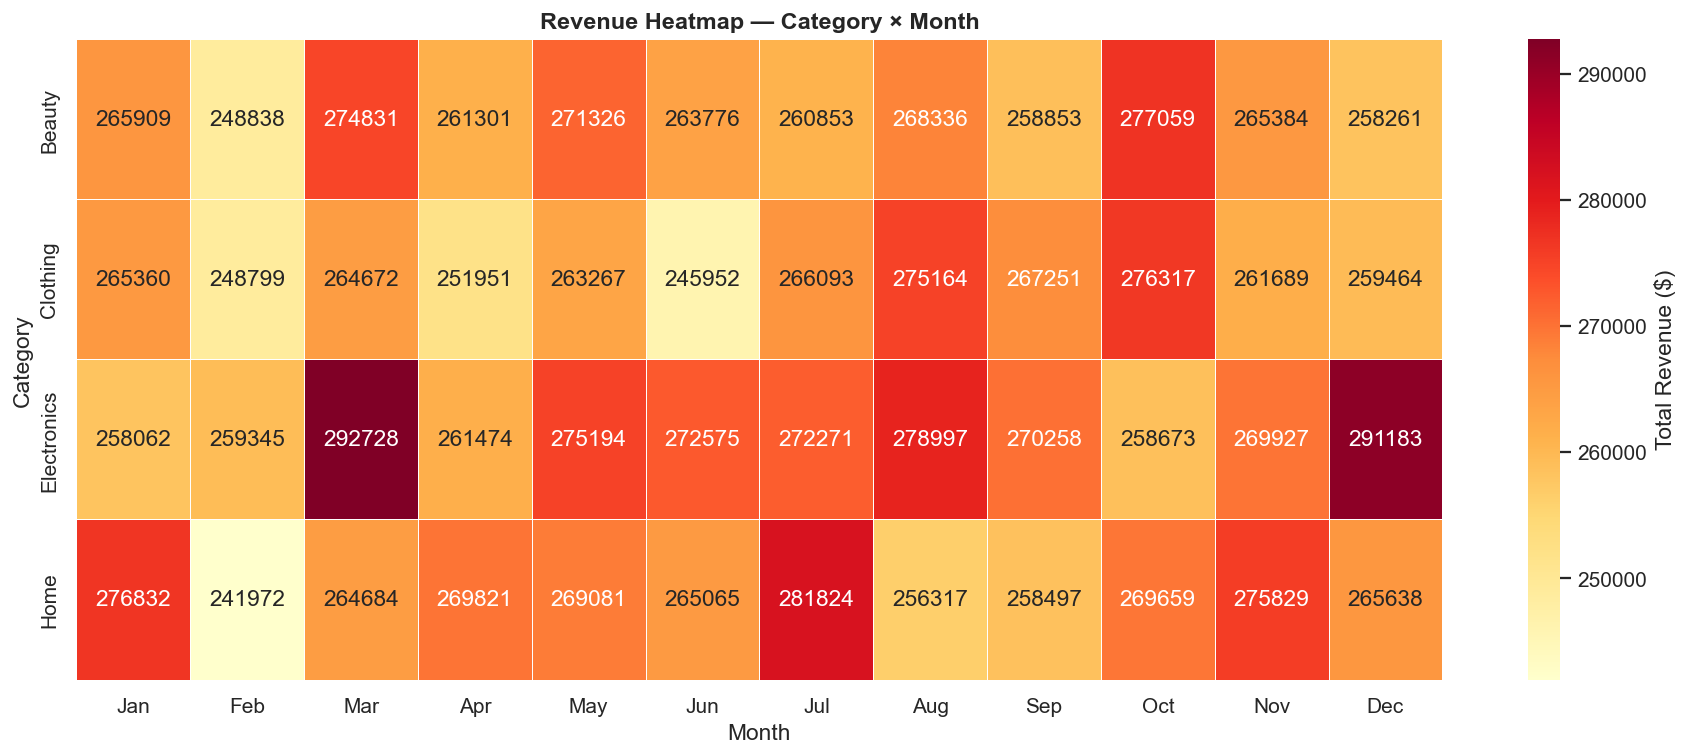

In [ ]:
# ── Month × Category heatmap ──────────────────────────────────────────────
if 'Month_Name' in df.columns and COL_CATEGORY and COL_AMOUNT:
    month_order_full = ['Jan','Feb','Mar','Apr','May','Jun',
                        'Jul','Aug','Sep','Oct','Nov','Dec']
    pivot_mc = df.pivot_table(index=COL_CATEGORY, columns='Month_Name',
                               values=COL_AMOUNT, aggfunc='sum')
    existing_months = [m for m in month_order_full if m in pivot_mc.columns]
    pivot_mc = pivot_mc[existing_months]
    
    fig, ax = plt.subplots(figsize=(14, 6))
    sns.heatmap(pivot_mc, annot=True, fmt='.0f', cmap='YlOrRd',
                linewidths=0.4, ax=ax,
                cbar_kws={'label': 'Total Revenue ($)'})
    ax.set_title('Revenue Heatmap — Category × Month', fontsize=13, fontweight='bold')
    ax.set_xlabel('Month')
    plt.tight_layout()
    plt.show()

## 8. RFM Customer Segmentation

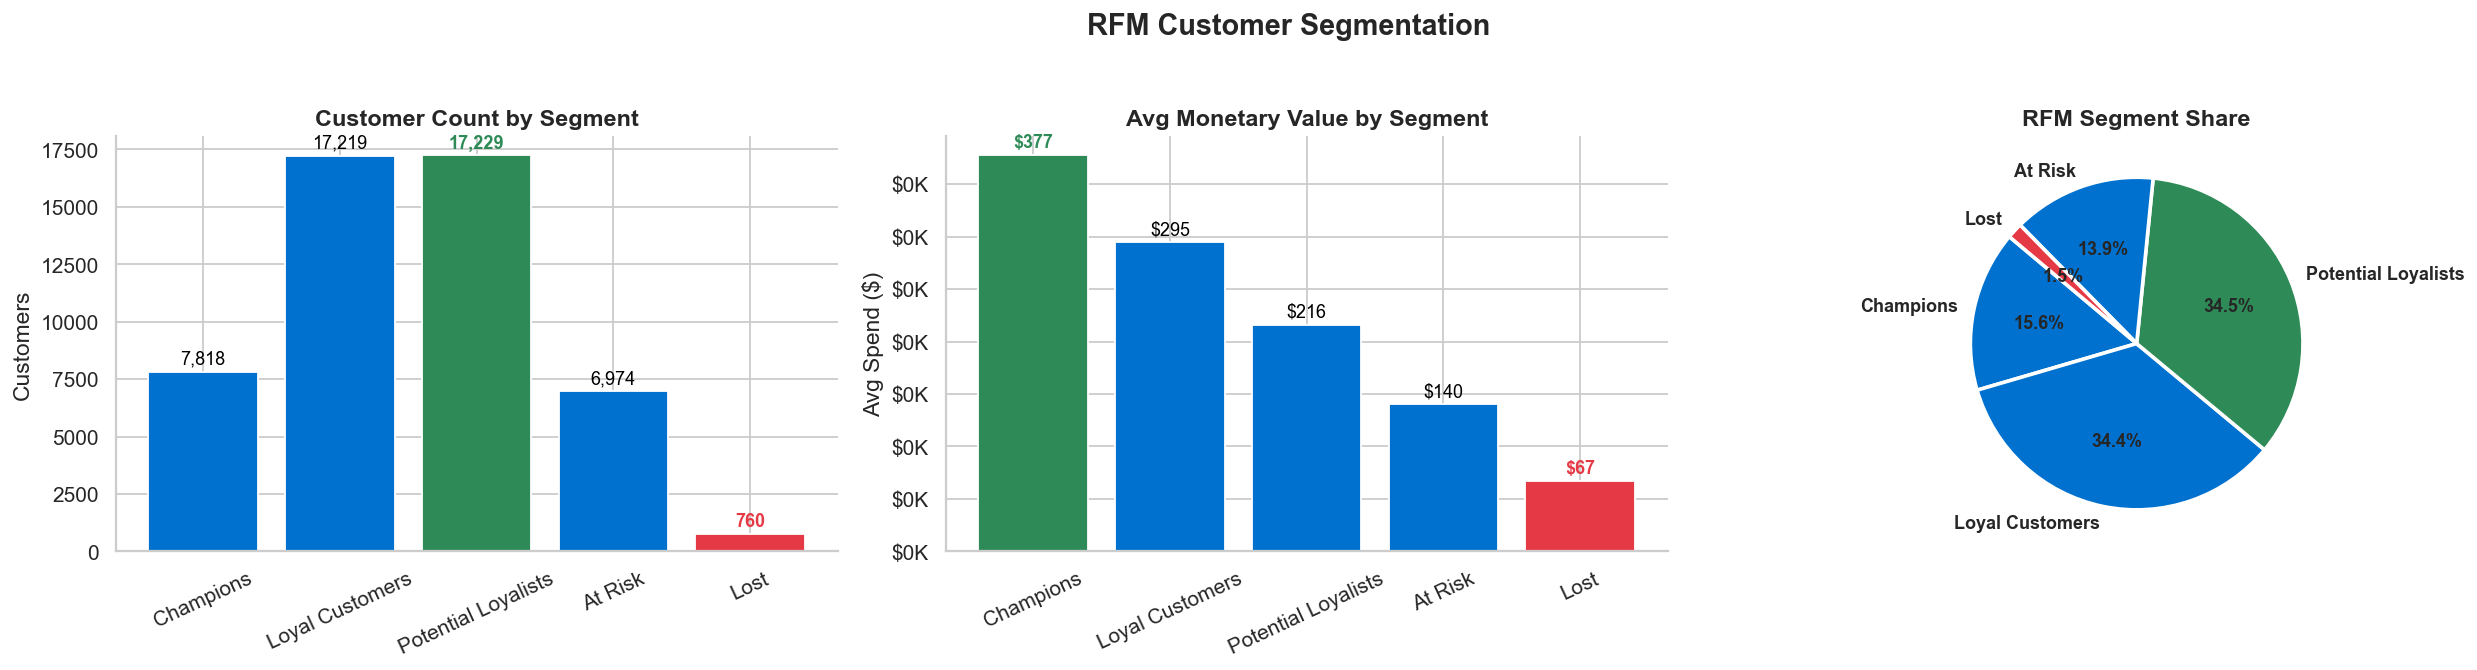


RFM Segment Summary:


,Recency,Frequency,Monetary
Segment,,,
Champions,92.65,1.0,377.23
Loyal Customers,154.63,1.0,294.74
Potential Loyalists,211.76,1.0,216.20
At Risk,270.15,1.0,140.00
Lost,320.29,1.0,67.26


In [ ]:
# ── RFM Analysis ──────────────────────────────────────────────────────────
if COL_CUST_ID and date_cols and COL_AMOUNT:

    dc = date_cols[0]
    snapshot_date = df[dc].max() + pd.Timedelta(days=1)

    rfm = df.groupby(COL_CUST_ID).agg(
        Recency   = (dc, lambda x: (snapshot_date - x.max()).days),
        Frequency = (dc, 'count'),
        Monetary  = (COL_AMOUNT, 'sum')
    ).reset_index()

    # ------------------------------------------------
    # SCORE
    # ------------------------------------------------
    rfm['R_Score'] = pd.qcut(
        rfm['Recency'],
        4,
        labels=[4, 3, 2, 1]
    ).astype(int)

    rfm['F_Score'] = pd.qcut(
        rfm['Frequency'].rank(method='first'),
        4,
        labels=[1, 2, 3, 4]
    ).astype(int)

    rfm['M_Score'] = pd.qcut(
        rfm['Monetary'],
        4,
        labels=[1, 2, 3, 4]
    ).astype(int)

    rfm['RFM_Score'] = (
        rfm['R_Score'] +
        rfm['F_Score'] +
        rfm['M_Score']
    )

    # ------------------------------------------------
    # SEGMENTS
    # ------------------------------------------------
    def rfm_segment(score):
        if score >= 10:
            return 'Champions'
        elif score >= 8:
            return 'Loyal Customers'
        elif score >= 6:
            return 'Potential Loyalists'
        elif score >= 4:
            return 'At Risk'
        else:
            return 'Lost'

    rfm['Segment'] = rfm['RFM_Score'].apply(rfm_segment)

    seg_order = [
        'Champions',
        'Loyal Customers',
        'Potential Loyalists',
        'At Risk',
        'Lost'
    ]

    seg_vc = (
        rfm['Segment']
        .value_counts()
        .reindex(seg_order)
        .dropna()
    )

    seg_monetary = (
        rfm.groupby('Segment')['Monetary']
        .mean()
        .reindex(seg_order)
        .dropna()
    )

    WALMART_GREEN = '#2E8B57'
    WALMART_RED   = '#E63946'


    # helper
    def highlight_colors(series):
        max_idx = series.idxmax()
        min_idx = series.idxmin()

        colors = []
        for idx in series.index:
            if idx == max_idx:
                colors.append(WALMART_GREEN)
            elif idx == min_idx:
                colors.append(WALMART_RED)
            else:
                colors.append(WALMART_BLUE)

        return colors, max_idx, min_idx


    fig, axes = plt.subplots(1, 3, figsize=(20, 5))


    # =====================================================
    # 1) CUSTOMER COUNT
    # =====================================================
    colors1, max1, min1 = highlight_colors(seg_vc)

    bars = axes[0].bar(
        seg_vc.index,
        seg_vc.values,
        color=colors1,
        edgecolor='white',
        linewidth=1
    )

    ymax = seg_vc.max()

    for i, (idx, val) in enumerate(seg_vc.items()):

        color = (
            WALMART_GREEN if idx == max1 else
            WALMART_RED if idx == min1 else
            'black'
        )

        weight = 'bold' if idx in [max1, min1] else 'normal'

        axes[0].text(
            i,
            val + ymax * 0.02,
            f'{val:,}',
            ha='center',
            fontsize=10,
            color=color,
            fontweight=weight
        )

    axes[0].set_title(
        'Customer Count by Segment',
        fontweight='bold'
    )
    axes[0].set_ylabel('Customers')
    axes[0].tick_params(axis='x', rotation=25)


    # =====================================================
    # 2) MONETARY
    # =====================================================
    colors2, max2, min2 = highlight_colors(seg_monetary)

    bars = axes[1].bar(
        seg_monetary.index,
        seg_monetary.values,
        color=colors2,
        edgecolor='white',
        linewidth=1
    )

    ymax2 = seg_monetary.max()

    for i, (idx, val) in enumerate(seg_monetary.items()):

        color = (
            WALMART_GREEN if idx == max2 else
            WALMART_RED if idx == min2 else
            'black'
        )

        weight = 'bold' if idx in [max2, min2] else 'normal'

        label = (
            f'${val/1e6:.2f}M'
            if val >= 1_000_000 else
            f'${val/1e3:.1f}K'
            if val >= 1000 else
            f'${val:.0f}'
        )

        axes[1].text(
            i,
            val + ymax2 * 0.02,
            label,
            ha='center',
            fontsize=10,
            color=color,
            fontweight=weight
        )

    axes[1].set_title(
        'Avg Monetary Value by Segment',
        fontweight='bold'
    )
    axes[1].set_ylabel('Avg Spend ($)')
    axes[1].tick_params(axis='x', rotation=25)

    axes[1].yaxis.set_major_formatter(
        mticker.FuncFormatter(
            lambda x, _:
            f'${x/1e6:.1f}M'
            if x >= 1_000_000 else
            f'${x/1e3:.0f}K'
        )
    )


    # =====================================================
    # 3) PIE
    # =====================================================
    colors3, _, _ = highlight_colors(seg_vc)

    wedges, texts, autotexts = axes[2].pie(
        seg_vc.values,
        labels=seg_vc.index,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors3,
        wedgeprops={
            'edgecolor': 'white',
            'linewidth': 2
        },
        textprops={
            'fontsize': 10,
            'fontweight': 'bold'
        }
    )

    axes[2].set_title(
        'RFM Segment Share',
        fontweight='bold'
    )


    # =====================================================
    plt.suptitle(
        'RFM Customer Segmentation',
        fontsize=16,
        fontweight='bold',
        y=1.03
    )

    plt.tight_layout()
    plt.show()


    print("\nRFM Segment Summary:")
    display(
        rfm.groupby('Segment')[
            ['Recency', 'Frequency', 'Monetary']
        ]
        .mean()
        .round(2)
        .reindex(seg_order)
        .dropna()
    )

else:
    print("ℹ RFM skipped — requires Customer ID + Date + Amount columns.")

## 9. Correlation & Feature Relationships

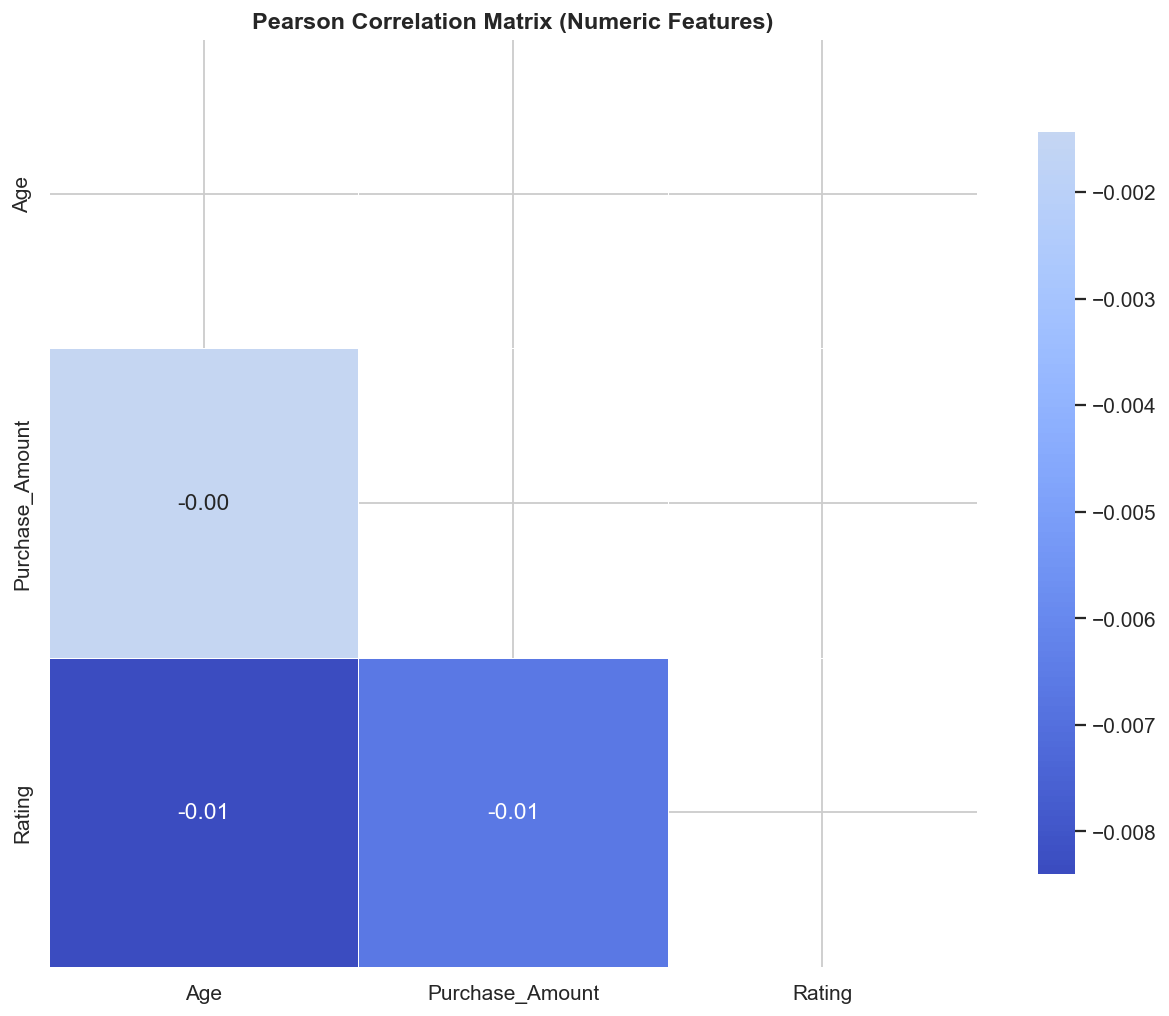

In [ ]:
# ── Numeric correlation heatmap ───────────────────────────────────────────
num_df = df.select_dtypes(include='number').drop(
    columns=[c for c in ['Year','Month'] if c in df.columns], errors='ignore'
)
if num_df.shape[1] >= 2:
    corr = num_df.corr()
    mask = np.triu(np.ones_like(corr, dtype=bool))
    
    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
                center=0, linewidths=0.5, ax=ax, square=True,
                cbar_kws={'shrink': 0.8})
    ax.set_title('Pearson Correlation Matrix (Numeric Features)', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

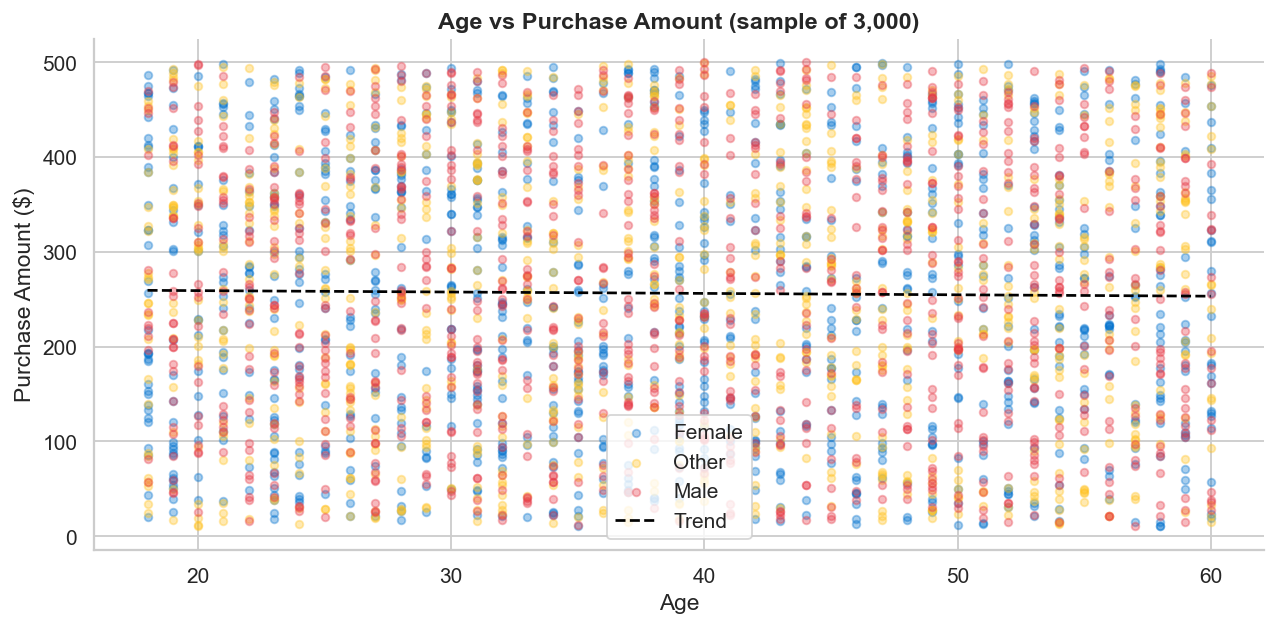

In [ ]:
# ── Scatter: Age vs Purchase Amount (coloured by gender) ──────────────────
if COL_AGE and COL_AMOUNT and COL_GENDER:
    sample = df.sample(min(3000, len(df)), random_state=42)
    fig, ax = plt.subplots(figsize=(10, 5))
    for i, g in enumerate(sample[COL_GENDER].unique()):
        sub = sample[sample[COL_GENDER] == g]
        ax.scatter(sub[COL_AGE], sub[COL_AMOUNT], alpha=0.35, s=18,
                   color=PALETTE[i], label=g)
    # Trend line
    z = np.polyfit(sample[COL_AGE].dropna(), sample[COL_AMOUNT].dropna(), 1)
    p = np.poly1d(z)
    x_line = np.linspace(sample[COL_AGE].min(), sample[COL_AGE].max(), 100)
    ax.plot(x_line, p(x_line), 'k--', linewidth=1.5, label='Trend')
    ax.set_title('Age vs Purchase Amount (sample of 3,000)')
    ax.set_xlabel(COL_AGE)
    ax.set_ylabel('Purchase Amount ($)')
    ax.legend()
    plt.tight_layout()
    plt.show()

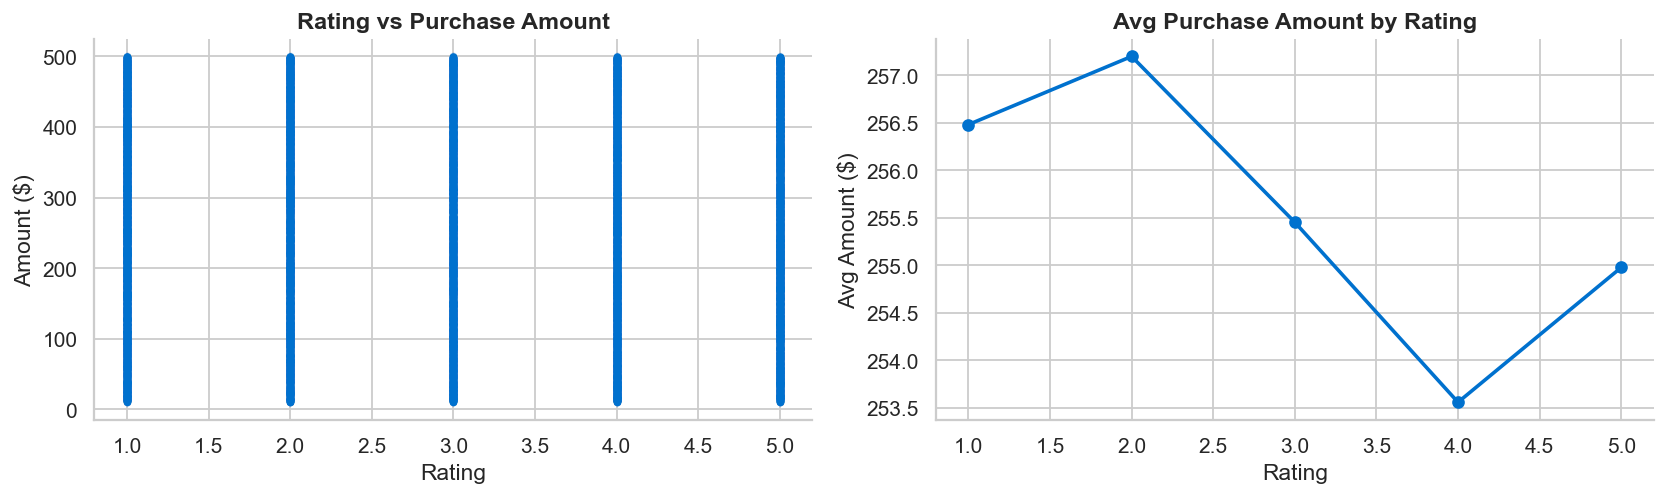

Pearson r (Rating vs Amount): -0.007  |  p-value: 0.1371


In [ ]:
# ── Rating vs Spend (if both exist) ──────────────────────────────────────
if COL_RATING and COL_AMOUNT:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    
    axes[0].scatter(df[COL_RATING], df[COL_AMOUNT], alpha=0.15, s=10, color=WALMART_BLUE)
    axes[0].set_title('Rating vs Purchase Amount')
    axes[0].set_xlabel('Rating')
    axes[0].set_ylabel('Amount ($)')
    
    avg_by_rating = df.groupby(COL_RATING)[COL_AMOUNT].mean()
    axes[1].plot(avg_by_rating.index, avg_by_rating.values,
                 marker='o', color=WALMART_BLUE, linewidth=2)
    axes[1].set_title('Avg Purchase Amount by Rating')
    axes[1].set_xlabel('Rating')
    axes[1].set_ylabel('Avg Amount ($)')
    
    plt.tight_layout()
    plt.show()
    
    r, p = stats.pearsonr(df[COL_RATING].dropna(), df[COL_AMOUNT].dropna())
    print(f'Pearson r (Rating vs Amount): {r:.3f}  |  p-value: {p:.4f}')

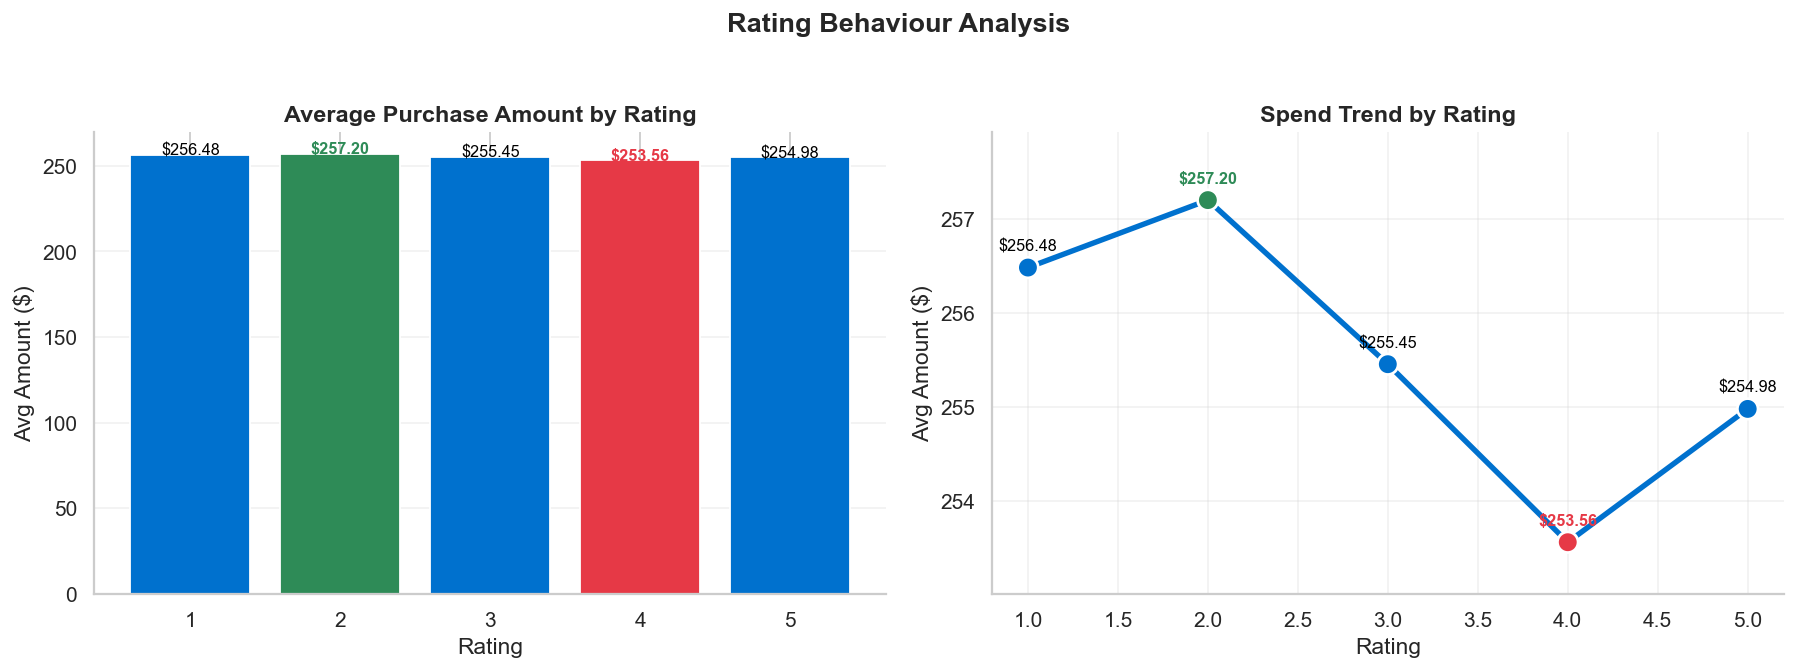

Pearson r: -0.007 | p-value: 0.1371


In [ ]:
# ── Rating vs Spend ──────────────────────────────────────────────────────
if COL_RATING and COL_AMOUNT:

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    WALMART_GREEN = '#2E8B57'
    WALMART_RED = '#E63946'

    plot_df = df[[COL_RATING, COL_AMOUNT]].dropna().copy()
    plot_df[COL_RATING] = plot_df[COL_RATING].astype(int)

    avg_by_rating = (
        plot_df.groupby(COL_RATING)[COL_AMOUNT]
        .mean()
        .sort_index()
    )

    max_idx = avg_by_rating.idxmax()
    min_idx = avg_by_rating.idxmin()
    max_val = avg_by_rating.max()
    min_val = avg_by_rating.min()
    spread = max_val - min_val

    if spread == 0:
        spread = max_val * 0.02


    # ==================================================
    # LEFT : BAR CHART
    # ==================================================
    bar_colors = [
        WALMART_GREEN if i == max_idx else
        WALMART_RED if i == min_idx else
        WALMART_BLUE
        for i in avg_by_rating.index
    ]

    bars = axes[0].bar(
        avg_by_rating.index,
        avg_by_rating.values,
        color=bar_colors,
        edgecolor='white',
        linewidth=1
    )

    # labels
    for idx, val in avg_by_rating.items():

        txt_color = (
            WALMART_GREEN if idx == max_idx else
            WALMART_RED if idx == min_idx else
            'black'
        )

        fw = 'bold' if idx in [max_idx, min_idx] else 'normal'

        axes[0].text(
            idx,
            val + spread * 0.05,
            f'${val:.2f}',
            ha='center',
            fontsize=9,
            color=txt_color,
            fontweight=fw
        )

    axes[0].set_title(
        'Average Purchase Amount by Rating',
        fontsize=13,
        fontweight='bold'
    )
    axes[0].set_xlabel('Rating')
    axes[0].set_ylabel('Avg Amount ($)')
    axes[0].grid(axis='y', alpha=0.25)


    # ==================================================
    # RIGHT : LINE TREND
    # ==================================================
    axes[1].plot(
        avg_by_rating.index,
        avg_by_rating.values,
        color=WALMART_BLUE,
        linewidth=3,
        zorder=1
    )

    point_colors = [
        WALMART_GREEN if i == max_idx else
        WALMART_RED if i == min_idx else
        WALMART_BLUE
        for i in avg_by_rating.index
    ]

    axes[1].scatter(
        avg_by_rating.index,
        avg_by_rating.values,
        s=130,
        c=point_colors,
        edgecolors='white',
        linewidth=1.5,
        zorder=3
    )

    # labels
    for idx, val in avg_by_rating.items():

        txt_color = (
            WALMART_GREEN if idx == max_idx else
            WALMART_RED if idx == min_idx else
            'black'
        )

        fw = 'bold' if idx in [max_idx, min_idx] else 'normal'

        axes[1].text(
            idx,
            val + spread * 0.05,
            f'${val:.2f}',
            ha='center',
            fontsize=9,
            color=txt_color,
            fontweight=fw
        )

    axes[1].set_ylim(
        min_val - spread * 0.15,
        max_val + spread * 0.20
    )

    axes[1].set_title(
        'Spend Trend by Rating',
        fontsize=13,
        fontweight='bold'
    )
    axes[1].set_xlabel('Rating')
    axes[1].set_ylabel('Avg Amount ($)')
    axes[1].grid(alpha=0.25)


    # ==================================================
    plt.suptitle(
        'Rating Behaviour Analysis',
        fontsize=15,
        fontweight='bold',
        y=1.03
    )

    plt.tight_layout()
    plt.show()


    # correlation
    clean = plot_df[[COL_RATING, COL_AMOUNT]]

    r, pval = stats.pearsonr(
        clean[COL_RATING],
        clean[COL_AMOUNT]
    )

    print(f'Pearson r: {r:.3f} | p-value: {pval:.4f}')

## 10. Key Insights Summary

In [ ]:
print('=' * 65)
print('  WALMART CUSTOMER PURCHASE BEHAVIOR — KEY INSIGHTS')
print('=' * 65)

print(f'\n📦 DATASET')
print(f'   Total records     : {len(df):,}')
print(f'   Columns           : {df.shape[1]}')

if COL_AMOUNT:
    print(f'\n💰 PURCHASE AMOUNT')
    print(f'   Mean spend        : ${df[COL_AMOUNT].mean():,.2f}')
    print(f'   Median spend      : ${df[COL_AMOUNT].median():,.2f}')
    print(f'   Total revenue     : ${df[COL_AMOUNT].sum():,.0f}')
    print(f'   Distribution skew : {df[COL_AMOUNT].skew():.3f} ({"right" if df[COL_AMOUNT].skew()>0 else "left"}-skewed)')

if COL_GENDER:
    top_gender = df[COL_GENDER].value_counts().index[0]
    top_gender_pct = df[COL_GENDER].value_counts(normalize=True).iloc[0] * 100
    print(f'\n👥 DEMOGRAPHICS')
    print(f'   Dominant gender   : {top_gender} ({top_gender_pct:.1f}%)')

if COL_AGE:
    print(f'   Age range         : {int(df[COL_AGE].min())} – {int(df[COL_AGE].max())} yrs')
    print(f'   Avg age           : {df[COL_AGE].mean():.1f} yrs')

if COL_CATEGORY:
    top_cat = df[COL_CATEGORY].value_counts().index[0]
    print(f'\n🛍️  PRODUCTS')
    print(f'   Top category      : {top_cat}')
    if COL_AMOUNT:
        highest_rev_cat = df.groupby(COL_CATEGORY)[COL_AMOUNT].sum().idxmax()
        print(f'   Highest revenue   : {highest_rev_cat}')

if COL_PAYMENT:
    top_pay = df[COL_PAYMENT].value_counts().index[0]
    print(f'\n💳 PAYMENT')
    print(f'   Preferred method  : {top_pay}')

if COL_RATING:
    print(f'\n⭐ SATISFACTION')
    print(f'   Avg rating        : {df[COL_RATING].mean():.2f}')

if 'Segment' in df.columns or ('rfm' in dir()):
    try:
        champs_pct = (rfm['Segment'] == 'Champions').mean() * 100
        at_risk_pct = (rfm['Segment'] == 'At Risk').mean() * 100
        print(f'\n🎯 RFM SEGMENTATION')
        print(f'   Champions         : {champs_pct:.1f}% of customers')
        print(f'   At Risk           : {at_risk_pct:.1f}% of customers — need re-engagement')
    except Exception:
        pass

print('\n' + '=' * 65)

  WALMART CUSTOMER PURCHASE BEHAVIOR — KEY INSIGHTS

📦 DATASET
   Total records     : 50,000
   Columns           : 18

💰 PURCHASE AMOUNT
   Mean spend        : $255.53
   Median spend      : $255.05
   Total revenue     : $12,776,611
   Distribution skew : -0.003 (left-skewed)

👥 DEMOGRAPHICS
   Dominant gender   : Other (33.5%)
   Age range         : 18 – 60 yrs
   Avg age           : 38.9 yrs

🛍️  PRODUCTS
   Top category      : Electronics
   Highest revenue   : Electronics

💳 PAYMENT
   Preferred method  : Debit Card

⭐ SATISFACTION
   Avg rating        : 3.00

🎯 RFM SEGMENTATION
   Champions         : 15.6% of customers
   At Risk           : 13.9% of customers — need re-engagement

